# Trabajo Practico 1 - I302

El notebook sigue el orden de la consigna.
La idea fue dejar la logica reusable en `src/` y usar el notebook para mostrar el desarrollo, los resultados y las conclusiones.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str((PROJECT_ROOT / "src").resolve()))

from utils import (
    ajustar_modelo_con_preprocesamiento,
    calcular_learning_curve_modelo,
    construir_regularization_path,
    construir_ranking_features_candidatas,
    construir_tablas_coeficientes_extremos,
    cross_validate_lambdas_con_preprocesamiento,
    evaluar_curva_complejidad_features,
    evaluar_metricas_regularizacion_en_grilla,
    entrenar_modelo_regularizado_y_evaluar,
    entrenar_y_resumir_modelo,
    exportar_csv_inspeccion_modelos,
    preparar_features_para_modelo,
)
from data_splitting import train_val_split
from metrics import resumir_metricas_regresion
from models import RegresionLineal
from preprocessing import (
    agregar_features_candidatas_combinacionales,
    agregar_features_derivadas_m4,
    agregar_features_derivadas_m5,
    aplicar_imputacion_basica,
    aprender_mediana_edad_por_tipo,
    aprender_mediana_pisos_por_tipo,
    construir_dataset_base,
    obtener_configuracion_m4,
    obtener_configuracion_m5,
    preparar_matrices_para_modelado,
)
from visualization import (
    configurar_estilo_graficos,
    construir_matriz_mejora_relativa,
    graficar_comparacion_ecm,
    graficar_comparacion_metricas,
    graficar_correlaciones_por_zona,
    graficar_complejidad_features,
    graficar_curva_perdida,
    graficar_dispersion_precio_area_por_zona,
    graficar_eda_precio,
    graficar_importancia_coeficientes,
    graficar_learning_curves_modelos,
    graficar_m1_recta,
    graficar_matriz_mejora_relativa,
    graficar_metricas_regularizacion_vs_lambda,
    graficar_metricas_validacion,
    graficar_panel_cv_regularizacion,
    graficar_precio_m2_por_zona_y_tipo,
    graficar_ranking_features_candidatas,
    graficar_real_vs_predicho_panel,
    graficar_regularization_paths,
    graficar_residuos_panel,
)

configurar_estilo_graficos()
plt.rcParams["figure.max_open_warning"] = 0
pd.set_option("display.max_rows", 12)
pd.set_option("display.min_rows", 8)
pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

casas_dev = pd.read_csv(RAW_DIR / "casas_dev.csv")
casas_test = pd.read_csv(RAW_DIR / "casas_test.csv")
AREA_COL = next(col for col in casas_dev.columns if "rea" in col.lower())


## 1. Analisis Exploratorio de Datos


### 1.1) Inspeccion inicial del dataset y limpieza propuesta

Arranco mirando una muestra del dataset, los faltantes y algunos estadisticos basicos.
Con eso decido las primeras limpiezas y dejo separado el flujo que despues uso en train, validation y test.


In [2]:
print("Shape casas_dev:", casas_dev.shape)
print("Shape casas_test:", casas_test.shape)
print("Muestra aleatoria del dataset original:")
display(casas_dev.sample(5, random_state=42))

print("Valores faltantes en el dataset original:")
display(casas_dev.isna().sum().sort_values(ascending=False).to_frame("faltantes"))

columnas_resumen = [col for col in [AREA_COL, "metros_cubiertos", "ambientes", "pisos", "edad", "precio"] if col in casas_dev.columns]
print("Estadisticos descriptivos de las columnas numericas principales:")
display(casas_dev[columnas_resumen].describe().T)

dataset_base_dev = construir_dataset_base(casas_dev)
dataset_base_test = construir_dataset_base(casas_test)
dataset_base_dev.to_csv(PROCESSED_DIR / "dataset_base_dev.csv", index=False)
dataset_base_test.to_csv(PROCESSED_DIR / "dataset_base_test.csv", index=False)

df_train_base, df_validation_base = train_val_split(dataset_base_dev, train_ratio=0.8, seed=42)
mediana_pisos_por_tipo = aprender_mediana_pisos_por_tipo(df_train_base)
mediana_edad_por_tipo = aprender_mediana_edad_por_tipo(df_train_base)

df_train = aplicar_imputacion_basica(df_train_base, mediana_pisos_por_tipo, mediana_edad_por_tipo)
df_validation = aplicar_imputacion_basica(df_validation_base, mediana_pisos_por_tipo, mediana_edad_por_tipo)
df_test = aplicar_imputacion_basica(dataset_base_test, mediana_pisos_por_tipo, mediana_edad_por_tipo)

resumen_base = pd.DataFrame(
    [
        {"split": "train", "filas": len(df_train)},
        {"split": "validation", "filas": len(df_validation)},
        {"split": "test", "filas": len(df_test)},
    ]
)
print("Resumen luego de construir el dataset base e imputar:")
display(resumen_base)

Shape casas_dev: (1600, 11)
Shape casas_test: (400, 11)
Muestra aleatoria del dataset original:


,precio,tipo,Área,metros_cubiertos,unidades,ambientes,pisos,pileta,lat,lon,edad
526,"65,593.9268",casa,211.9347,133.6988,m2,10,3.0000,True,-34.7770,-58.1942,40.3586
354,"20,449.8286",casa,203.2447,148.4482,m2,10,3.0000,False,-34.7259,-58.2634,1.0000
168,"3,490.4653",casa,233.5568,108.4339,m2,4,1.0000,False,-34.8577,-58.2773,1.0000
135,"188,443.7384",depto,769.0753,766.5052,sqft,7,NaN,False,40.6986,-74.0250,12.0791
937,"141,276.5108",depto,632.9397,607.7475,sqft,5,NaN,False,40.6976,-74.0087,1.9040


Valores faltantes en el dataset original:


,faltantes
pisos,852
edad,149
precio,55
Área,0
tipo,0
unidades,0
metros_cubiertos,0
ambientes,0
pileta,0
lat,0


Estadisticos descriptivos de las columnas numericas principales:


,count,mean,std,min,25%,50%,75%,max
Área,"1,600.0000",441.7937,312.0593,54.2148,213.2980,251.3710,734.0533,"2,475.7186"
metros_cubiertos,"1,600.0000",389.0797,316.4263,52.6127,114.2956,166.4338,712.5034,"1,553.9654"
ambientes,"1,600.0000",6.9150,2.4913,1.0000,5.0000,7.0000,10.0000,10.0000
pisos,748.0000,2.6176,0.6713,1.0000,2.0000,3.0000,3.0000,3.0000
edad,"1,451.0000",22.9211,21.1607,1.0000,7.0047,13.1017,37.9294,96.4400
precio,"1,545.0000","93,343.6925","96,555.2460",0.0000,"15,425.3065","43,042.3418","169,055.6396","769,962.6736"


Resumen luego de construir el dataset base e imputar:


,split,filas
0,train,1190
1,validation,298
2,test,372


**Respuesta al 1.1.**

Las columnas que mas conviene revisar son `unidades`, `area`, `metros_cubiertos`, `pisos`, `edad` y `precio`.
Tome como limpieza base la conversion de superficies, el manejo de faltantes y el filtrado de precios no validos.
Los precios bajos los deje visibles para analizarlos despues y no descartarlos sin mirar.


### 1.2) Histogramas, boxplots y scatterplots

Para esta parte use un `pairplot`, algunos histogramas y boxplots, y graficos separados por zona.
La idea fue cubrir lo que pide la consigna sin dejar todo en un solo grafico.


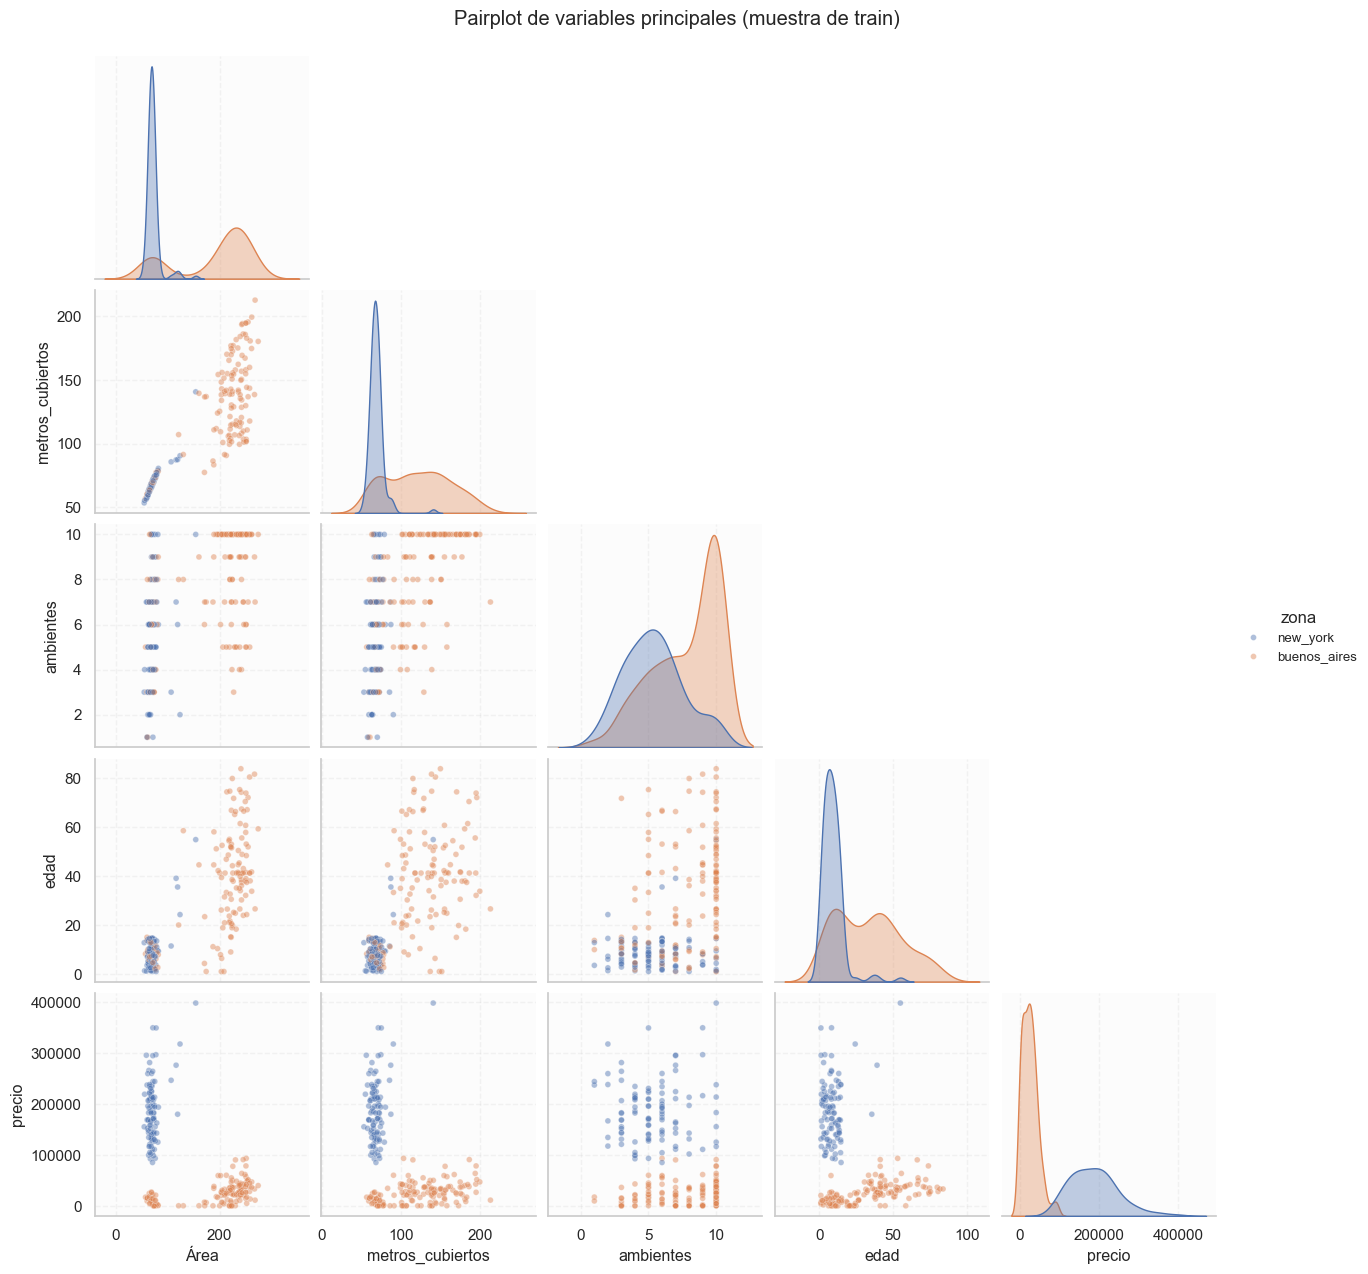

In [3]:
columnas_pairplot = [col for col in [AREA_COL, "metros_cubiertos", "ambientes", "edad", "precio", "zona"] if col in df_train.columns]
muestra_pairplot = df_train[columnas_pairplot].sample(min(250, len(df_train)), random_state=42)
grid = sns.pairplot(
    muestra_pairplot,
    vars=[AREA_COL, "metros_cubiertos", "ambientes", "edad", "precio"],
    hue="zona",
    corner=True,
    plot_kws={"alpha": 0.45, "s": 18},
    diag_kws={"fill": True, "alpha": 0.35},
)
grid.fig.suptitle("Pairplot de variables principales (muestra de train)", y=1.02)
plt.show()


**Lectura del pairplot.**

A simple vista ya aparece que `precio`, `area` y `metros_cubiertos` estan asociados, pero no de la
misma manera en las dos zonas. Tambien se ve que el mercado no es homogeneo: Buenos Aires y New York
forman submercados distintos.


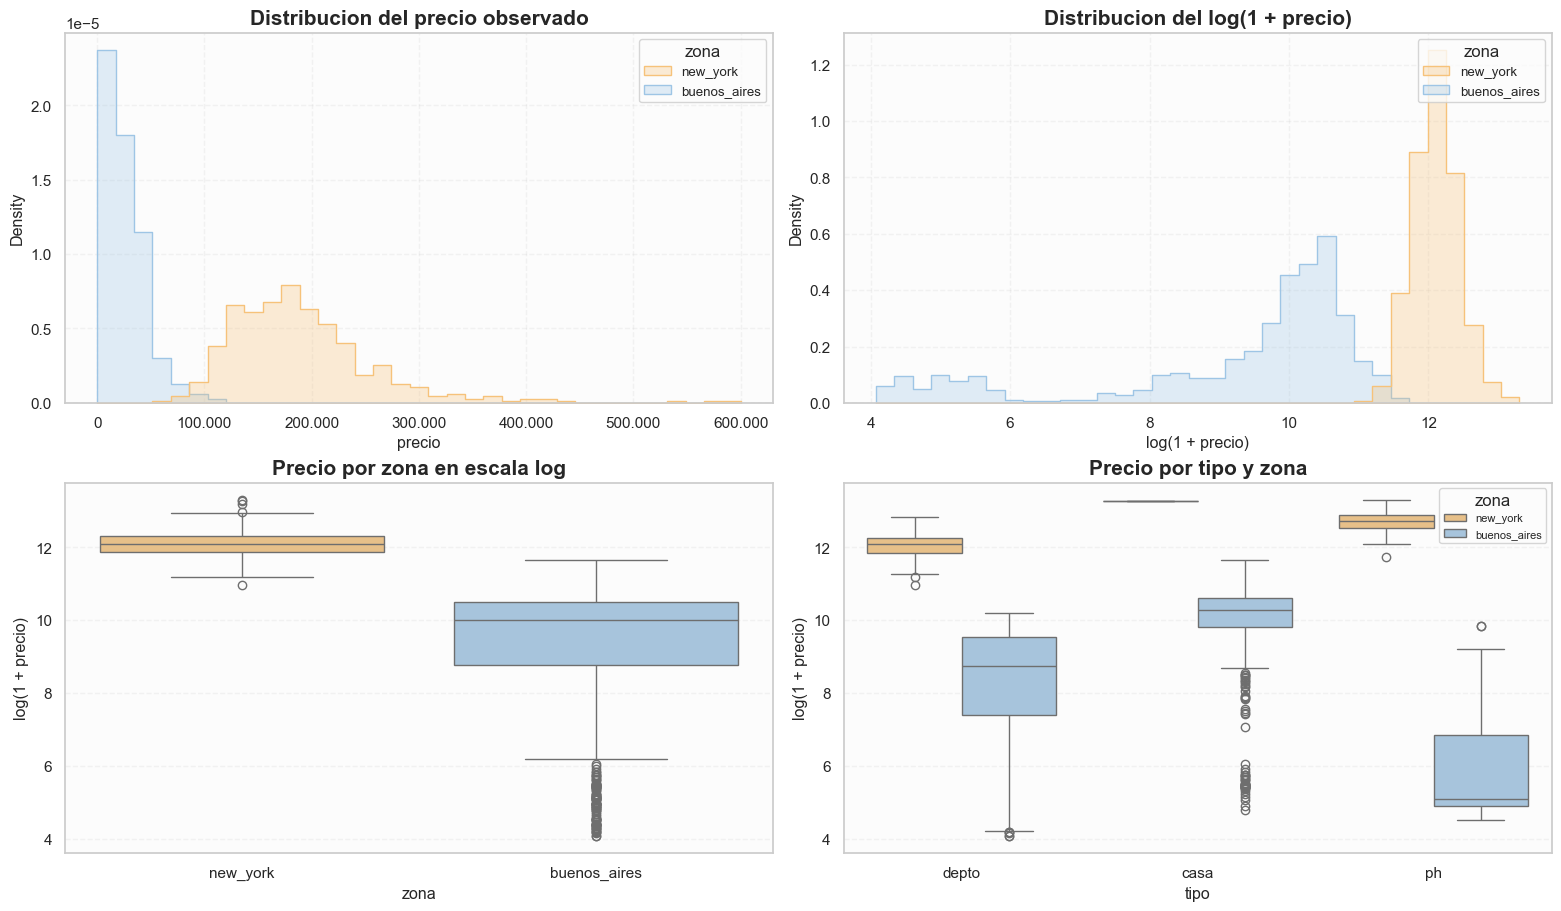

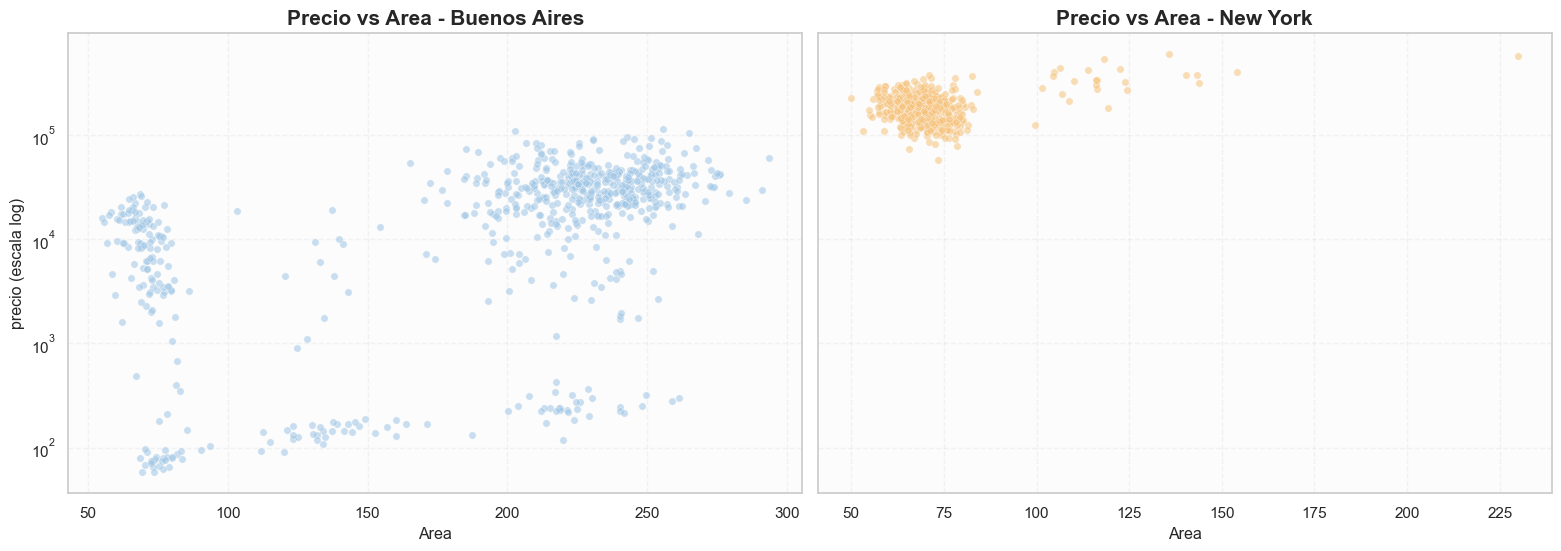

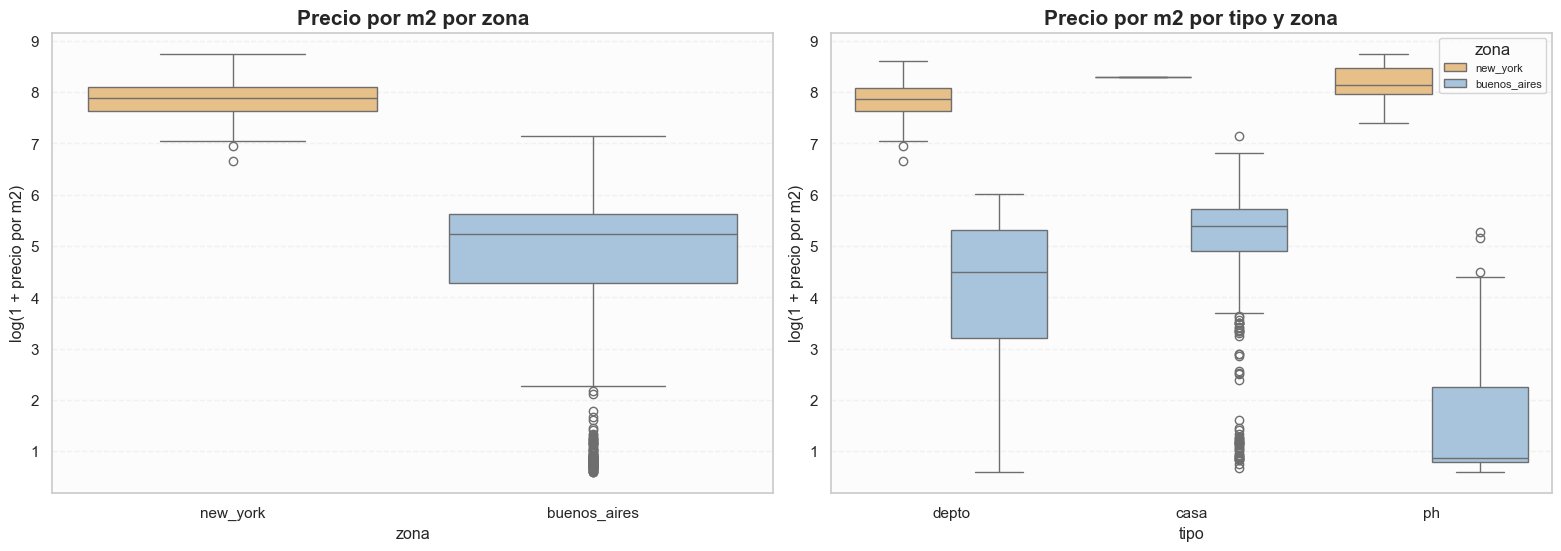

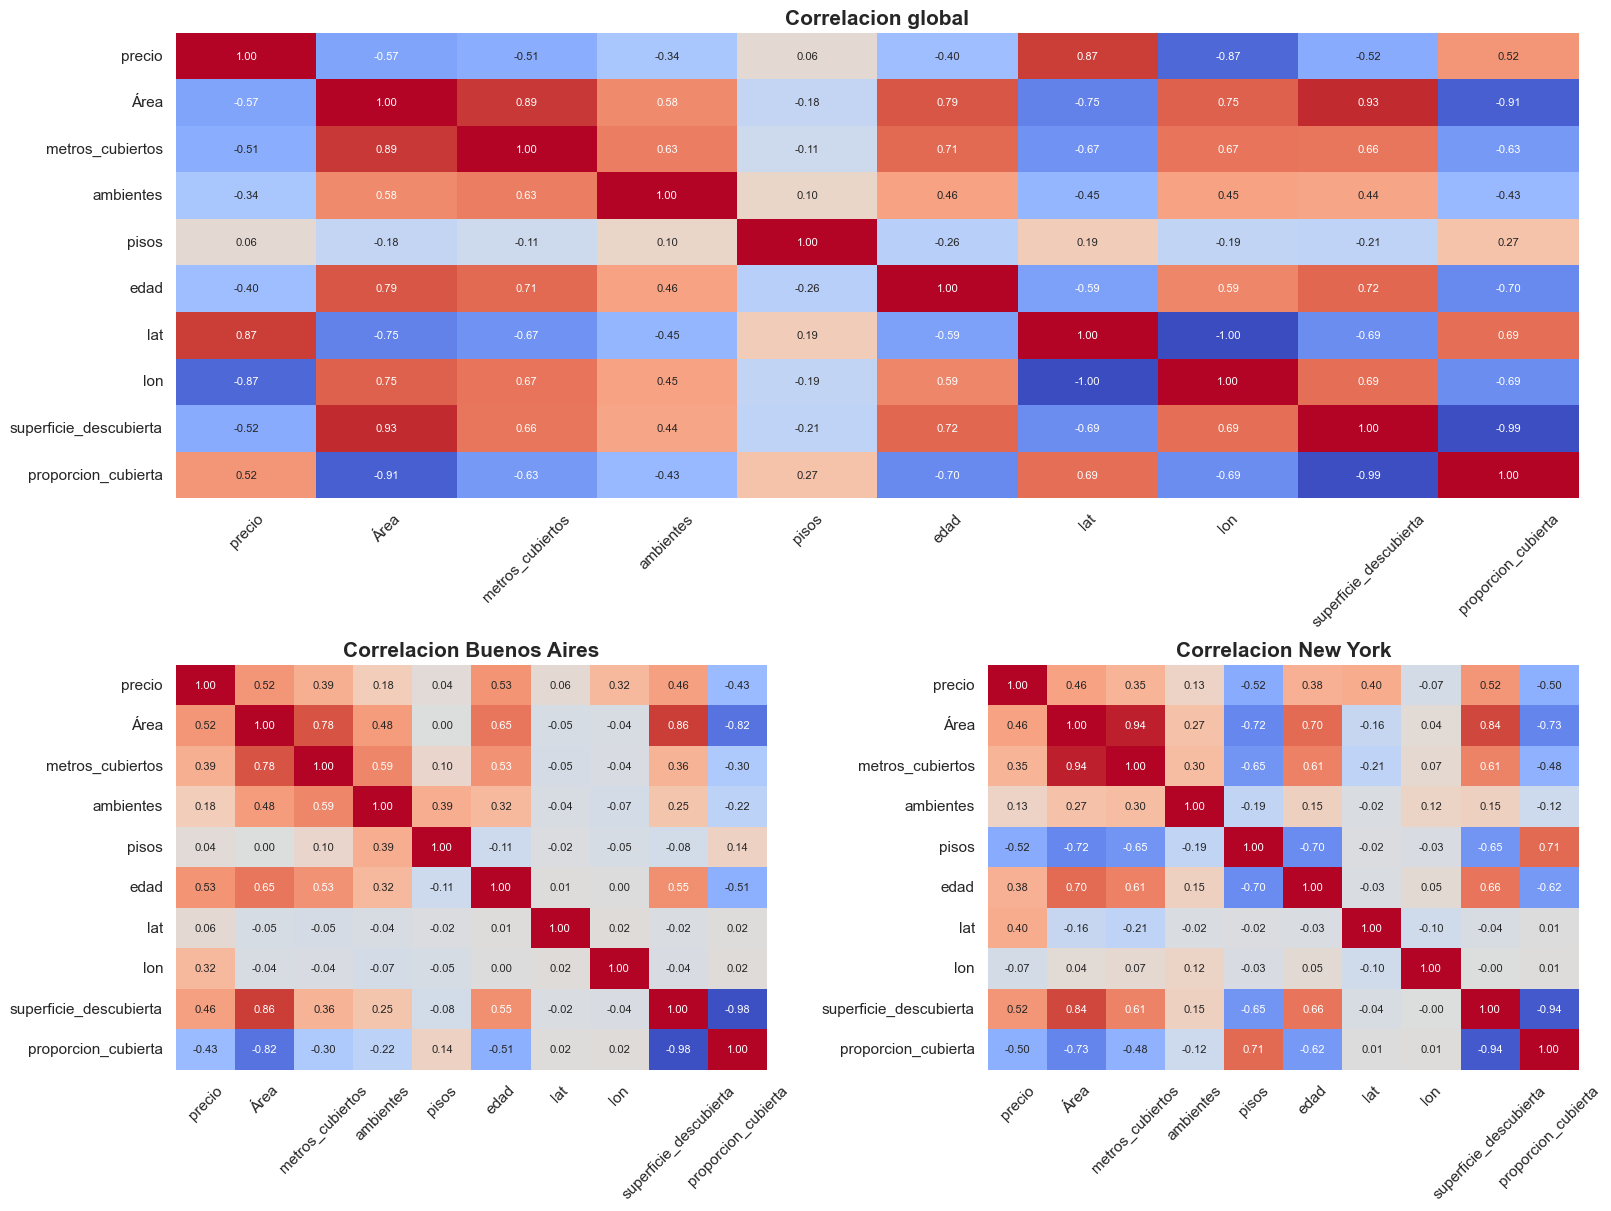

In [4]:
fig = graficar_eda_precio(df_train)
plt.show()

fig = graficar_dispersion_precio_area_por_zona(df_train)
plt.show()

fig = graficar_precio_m2_por_zona_y_tipo(df_train)
plt.show()

fig = graficar_correlaciones_por_zona(df_train)
plt.show()


**Respuesta al 1.2.**

A simple vista se ve que `precio` crece con `area` y con `metros_cubiertos`, pero no igual en las dos zonas.
Tambien hay diferencias claras entre Buenos Aires y New York, tanto en nivel de precios como en dispersion.
Por eso mas adelante separo zona en el analisis y sumo variables que ayuden a captar esas diferencias.


### 1.3) Split train/validation y normalizacion

El conjunto `casas_dev.csv` se divide en 80% para entrenamiento y 20% para validacion, usando semilla 42.
La normalizacion se aplica mas adelante dentro del pipeline de preparacion de features, aprendiendo
medias y desvios solo sobre train para evitar leakage.


In [5]:
resumen_split = pd.DataFrame(
    [
        {"split": "train", "filas": len(df_train), "proporcion": len(df_train) / len(dataset_base_dev)},
        {"split": "validation", "filas": len(df_validation), "proporcion": len(df_validation) / len(dataset_base_dev)},
    ]
)
print("Division 80/20 de casas_dev:")
display(resumen_split)

Division 80/20 de casas_dev:


,split,filas,proporcion
0,train,1190,0.7997
1,validation,298,0.2003


**Respuesta al 1.3.**

Mantengo el target `precio` en su escala original y normalizo solamente las variables explicativas numericas.
Asi se mejora el condicionamiento numerico de los algoritmos, pero las metricas y coeficientes sobre el target
siguen interpretandose directamente en dolares.


## 2. Implementacion Inicial

### 2.1) Clase `RegresionLineal`

La clase recibe `X` e `y` y permite entrenar por pseudo-inversa o por descenso por gradiente.
En ambos casos, los coeficientes quedan guardados en `self.coef`.

### 2.2) Funcion de perdida

La funcion de perdida implementada es el **Error Cuadratico Medio (ECM)**.

### 2.3) Verificacion de la implementacion

Para OLS deberian coincidir dos formas de ajuste:

- la solucion cerrada por pseudo-inversa;
- el descenso por gradiente sin regularizacion.



Metricas de train y validation para pseudo-inversa vs gradiente:


,modelo,split,metodo,RMSE,MAE,R2
0,M1,train,pseudoinversa,"77,374.6976","53,215.2447",0.3223
1,M1,train,gradiente,"77,374.6976","53,215.2448",0.3223
2,M1,validation,pseudoinversa,"93,036.0457","60,895.2249",0.2266
3,M1,validation,gradiente,"93,036.0458","60,895.2251",0.2266
4,M2,train,pseudoinversa,"77,349.7231","53,262.6819",0.3228
5,M2,train,gradiente,"77,349.7231","53,262.6815",0.3228
6,M2,validation,pseudoinversa,"92,930.4505","60,752.8207",0.2284
7,M2,validation,gradiente,"92,930.4507","60,752.8210",0.2284
8,M3,train,pseudoinversa,"43,252.1814","29,468.2374",0.7882
9,M3,train,gradiente,"43,252.1814","29,468.2347",0.7882


Cuadro de pesos para comparar pseudo-inversa vs gradiente:


,modelo,feature,peso_pseudoinversa,peso_gradiente,diferencia_absoluta
0,M1,intercepto,"94,638.4908","94,638.4895",0.0013
1,M1,Área,"-53,360.9912","-53,360.9904",0.0008
2,M2,intercepto,"95,728.1098","95,728.1061",0.0037
3,M2,Área,"-52,177.7976","-52,177.8016",0.0040
...,...,...,...,...,...
9,M3,edad,"8,309.8078","8,309.8012",0.0066
10,M3,tipo_depto,"-55,730.5450","-55,730.3144",0.2305
11,M3,tipo_ph,"7,471.1387","7,471.3042",0.1655
12,M3,zona_new_york,"196,137.1796","196,137.1755",0.0041


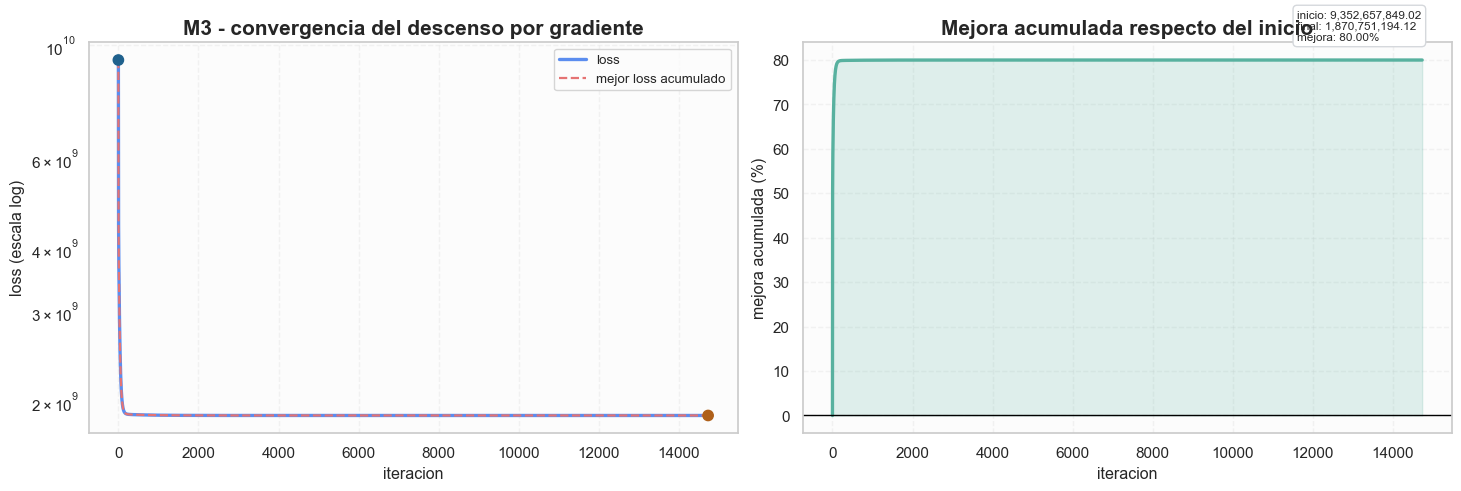

In [6]:
configuraciones_base = {
    "M1": {"numericas": [AREA_COL], "categoricas": []},
    "M2": {"numericas": [AREA_COL], "categoricas": ["pileta"]},
    "M3": {"numericas": [AREA_COL, "metros_cubiertos", "ambientes", "edad"], "categoricas": ["tipo", "zona"]},
}

comparaciones_ols = {}
tablas_metricas_ols = []
tablas_pesos_ols = []

for nombre_modelo, config in configuraciones_base.items():
    prep = preparar_features_para_modelo(df_train, df_validation, config["numericas"], config["categoricas"])
    X_train_modelo = prep["X_train"].values
    X_validation_modelo = prep["X_validation"].values
    y_train_modelo = df_train["precio"].values
    y_validation_modelo = df_validation["precio"].values
    feature_names = prep["X_train"].columns.tolist()

    modelo_pseudoinversa = RegresionLineal(
        X_train_modelo,
        y_train_modelo,
        feature_names=feature_names,
    )
    modelo_pseudoinversa.fit_pseudoinverse()

    modelo_gradiente = RegresionLineal(
        X_train_modelo,
        y_train_modelo,
        feature_names=feature_names,
    )
    modelo_gradiente.fit_gradient_descent(
        learning_rate=0.1,
        n_iterations=50000,
        tolerance=1e-10,
    )

    pred_train_pseudoinversa = modelo_pseudoinversa.predict(X_train_modelo)
    pred_validation_pseudoinversa = modelo_pseudoinversa.predict(X_validation_modelo)
    pred_train_gradiente = modelo_gradiente.predict(X_train_modelo)
    pred_validation_gradiente = modelo_gradiente.predict(X_validation_modelo)

    tabla_metricas_modelo = pd.DataFrame(
        [
            {
                "modelo": nombre_modelo,
                "split": "train",
                "metodo": "pseudoinversa",
                **resumir_metricas_regresion(y_train_modelo, pred_train_pseudoinversa),
            },
            {
                "modelo": nombre_modelo,
                "split": "train",
                "metodo": "gradiente",
                **resumir_metricas_regresion(y_train_modelo, pred_train_gradiente),
            },
            {
                "modelo": nombre_modelo,
                "split": "validation",
                "metodo": "pseudoinversa",
                **resumir_metricas_regresion(y_validation_modelo, pred_validation_pseudoinversa),
            },
            {
                "modelo": nombre_modelo,
                "split": "validation",
                "metodo": "gradiente",
                **resumir_metricas_regresion(y_validation_modelo, pred_validation_gradiente),
            },
        ]
    )
    tablas_metricas_ols.append(tabla_metricas_modelo)

    pesos_pseudoinversa = modelo_pseudoinversa.get_coefficient_dict()
    pesos_gradiente = modelo_gradiente.get_coefficient_dict()
    tabla_pesos_modelo = pd.DataFrame(
        {
            "modelo": nombre_modelo,
            "feature": list(pesos_pseudoinversa.keys()),
            "peso_pseudoinversa": list(pesos_pseudoinversa.values()),
            "peso_gradiente": [pesos_gradiente[feature] for feature in pesos_pseudoinversa.keys()],
        }
    )
    tabla_pesos_modelo["diferencia_absoluta"] = np.abs(
        tabla_pesos_modelo["peso_pseudoinversa"] - tabla_pesos_modelo["peso_gradiente"]
    )
    tablas_pesos_ols.append(tabla_pesos_modelo)

    comparaciones_ols[nombre_modelo] = {
        "prep": prep,
        "modelo_pseudoinversa": modelo_pseudoinversa,
        "modelo_gradiente": modelo_gradiente,
    }

tabla_metricas_ols = pd.concat(tablas_metricas_ols, ignore_index=True)
tabla_pesos_ols = pd.concat(tablas_pesos_ols, ignore_index=True)

print("Metricas de train y validation para pseudo-inversa vs gradiente:")
display(tabla_metricas_ols[["modelo", "split", "metodo", "RMSE", "MAE", "R2"]])
print("Cuadro de pesos para comparar pseudo-inversa vs gradiente:")
display(tabla_pesos_ols)

fig = graficar_curva_perdida(
    comparaciones_ols["M3"]["modelo_gradiente"].loss_history,
    titulo="M3 - convergencia del descenso por gradiente",
)
plt.show()


**Chequeo de consistencia OLS.**

La comparacion anterior se hace directamente sobre
`M1`, `M2` y `M3`. La idea es simple: si pseudo-inversa y descenso por gradiente devuelven
metricas practicamente iguales y pesos casi identicos (situacion que claramente se esta dando), entonces podemos asegurar que la implementacion de `RegresionLineal` queda validada 


## 3. Aplicacion de Modelos de Regresion

### 3.1) Modelos M1 y M2

Entreno `M1` usando solo `area`, y `M2` usando `area` y `pileta`.
En la misma tabla comparativa agrego `M3` para poder ver desde el inicio cuanto mejora
incorporar mas variables relevantes.

Para mantener claridad, en el flujo principal muestro:

- una tabla comparativa de M1, M2 y M3;
- la recta de M1, porque ilustra bien el caso mas simple;
- metricas por zona para los tres modelos base, porque la mezcla Buenos Aires/New York
  puede volver enganosa la metrica global;
- diagnosticos detallados de M3, porque es el mejor modelo base.

Tambien probe un ajuste heuristico del target como experimento aparte, pero en la
version final lo dejo solo documentado porque la mejora fue marginal y no cambia
las conclusiones del trabajo.

Comparacion observada entre M1, M2 y M3:


,modelo,RMSE_train,RMSE_validation,MAE_validation,R2_validation
0,M1,"77,374.6976","93,036.0457","60,895.2249",0.2266
1,M2,"77,349.7231","92,930.4505","60,752.8207",0.2284
2,M3,"43,252.1814","56,137.9689","32,279.2923",0.7184


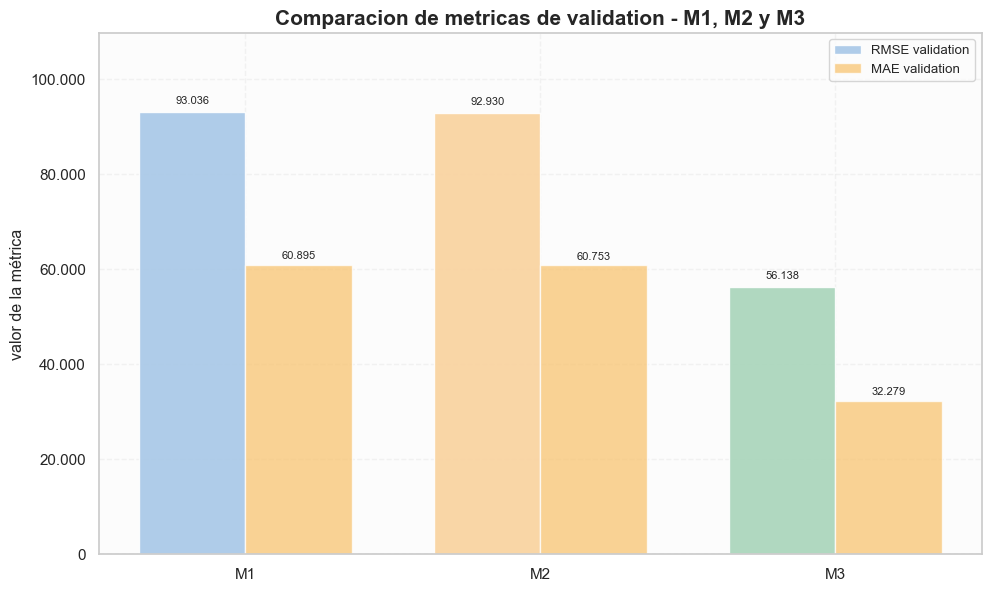

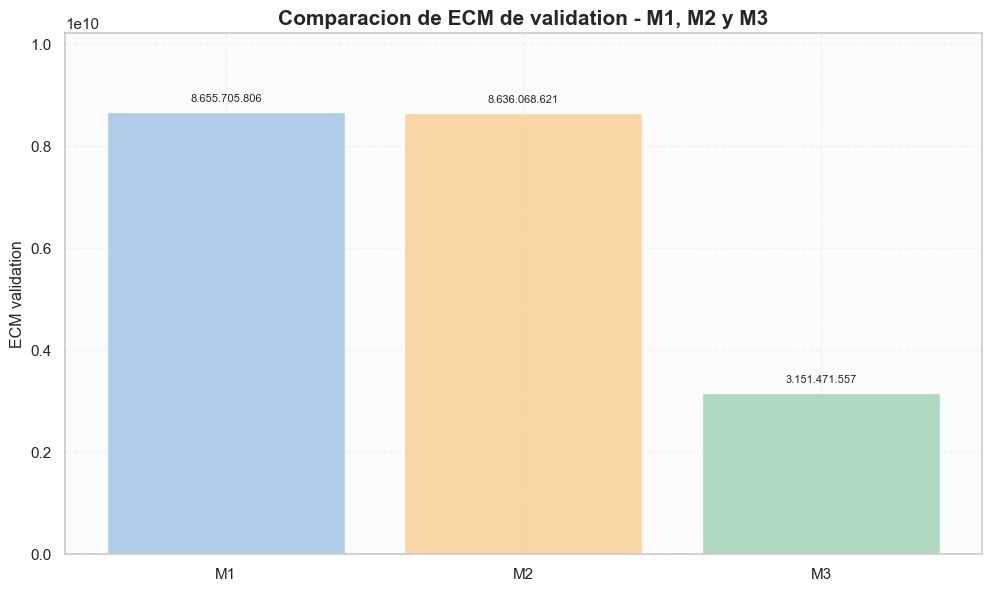

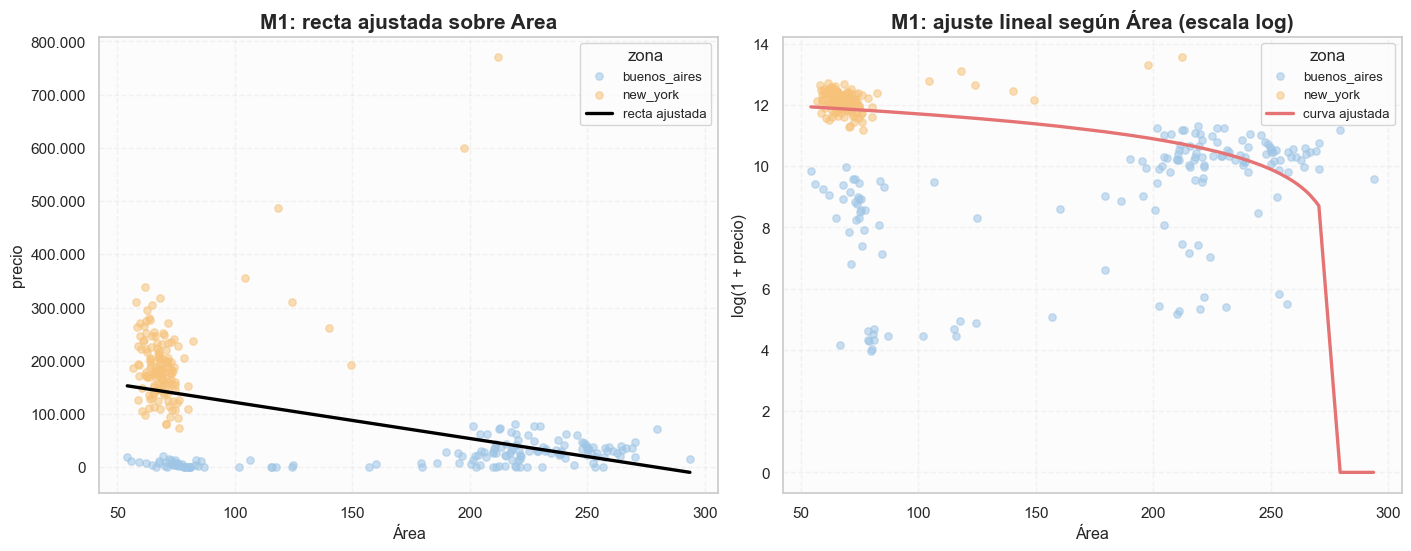

Metricas por zona para M1, M2 y M3:


,modelo,escenario_target,zona,MAE_validation,RMSE_validation,R2_validation
0,M1,precio_observado,new_york,"66,383.9432","108,763.2577",-0.6734
1,M1,precio_observado,buenos_aires,"55,831.4396","75,681.4002",-12.5588
2,M2,precio_observado,new_york,"66,332.0804","108,543.5486",-0.6666
3,M2,precio_observado,buenos_aires,"55,605.5037","75,722.9701",-12.5737
4,M3,precio_observado,new_york,"48,526.0740","77,929.5644",0.1409
5,M3,precio_observado,buenos_aires,"17,290.3261","21,356.7384",-0.0797


Coeficientes de M2:


,feature,coeficiente,abs_coeficiente
0,intercepto,"95,728.1098","95,728.1098"
1,Área,"-52,177.7976","52,177.7976"
2,pileta,"-5,920.7608","5,920.7608"


Coeficientes de M3:


,feature,coeficiente,abs_coeficiente
0,zona_new_york,"196,137.1796","196,137.1796"
1,tipo_depto,"-55,730.5450","55,730.5450"
2,intercepto,"39,988.6414","39,988.6414"
3,Área,"-12,329.7421","12,329.7421"
4,edad,"8,309.8078","8,309.8078"
5,tipo_ph,"7,471.1387","7,471.1387"
6,metros_cubiertos,"-1,847.3250","1,847.3250"
7,ambientes,775.6603,775.6603


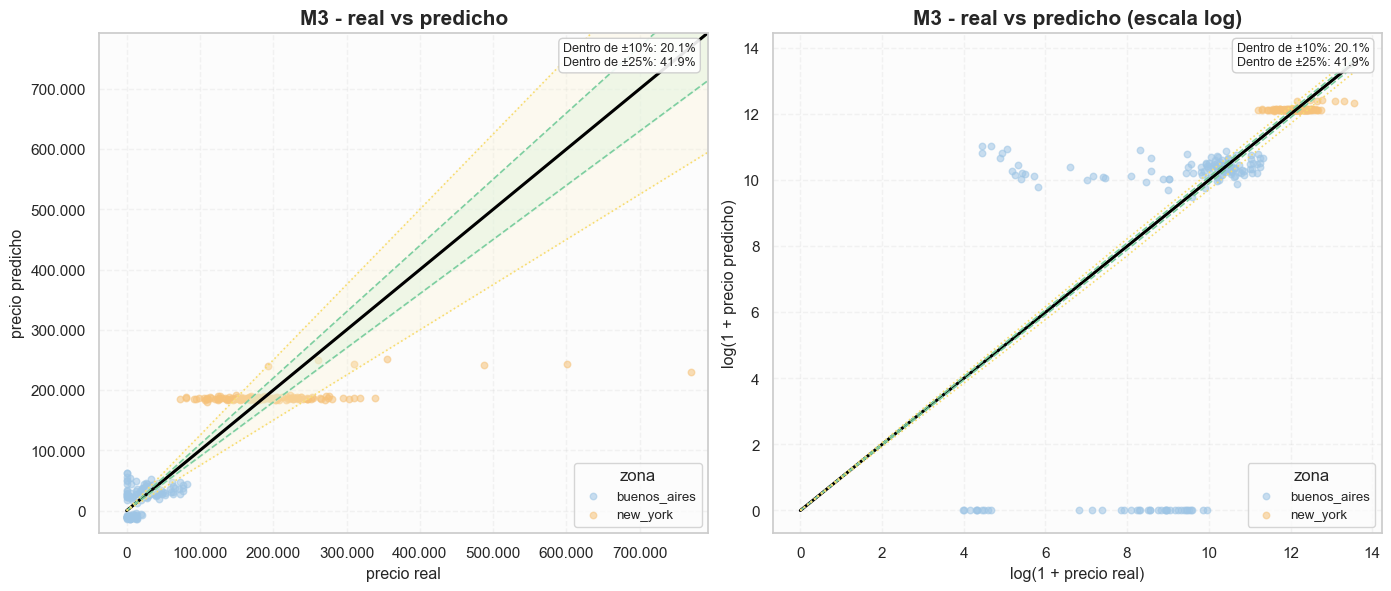

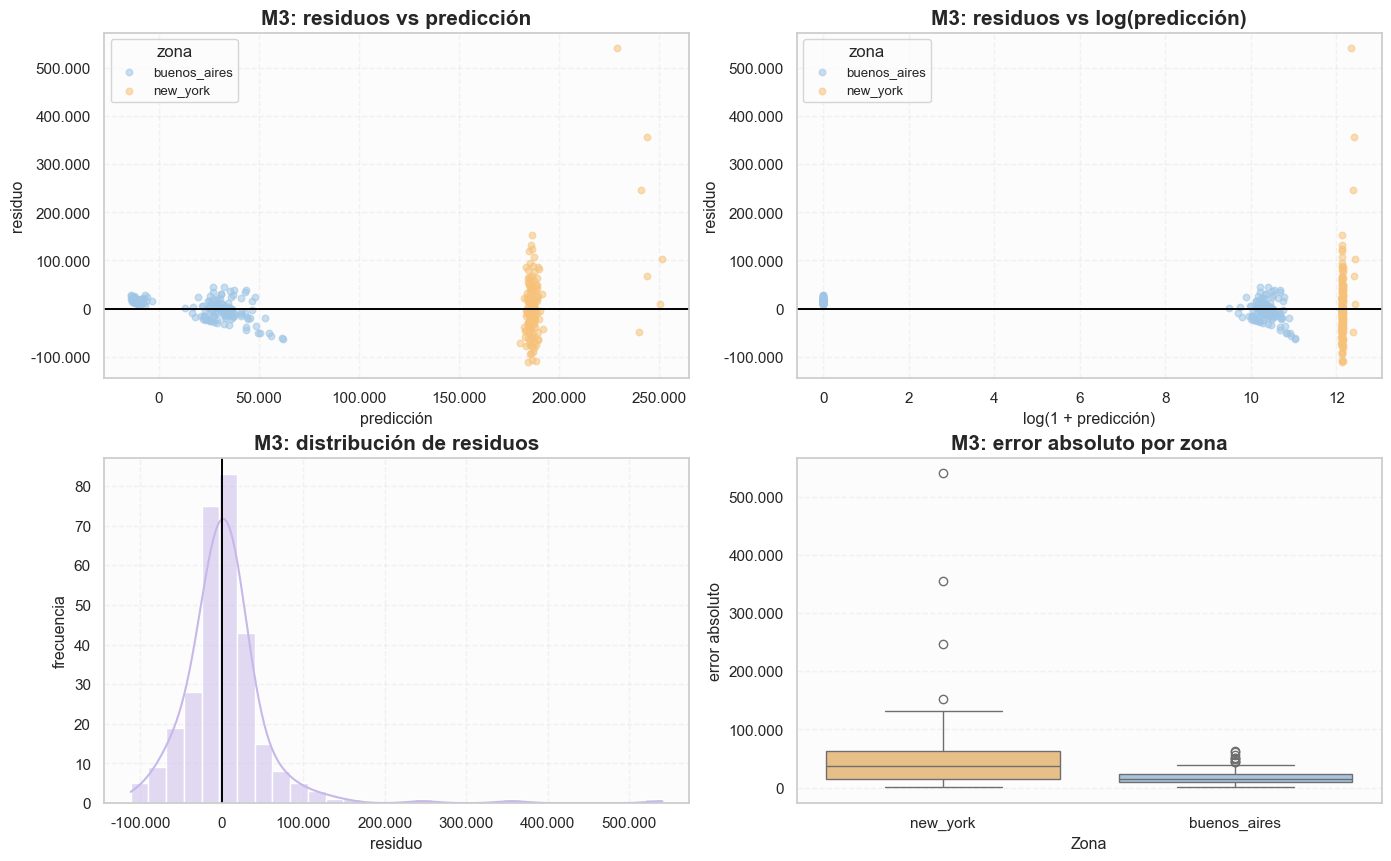

In [7]:
configuraciones_base = {
    "M1": {"numericas": [AREA_COL], "categoricas": []},
    "M2": {"numericas": [AREA_COL], "categoricas": ["pileta"]},
    "M3": {"numericas": [AREA_COL, "metros_cubiertos", "ambientes", "edad"], "categoricas": ["tipo", "zona"]},
}

artefactos_base = {}
resumenes_base = []

for nombre_modelo, config in configuraciones_base.items():
    prep = preparar_features_para_modelo(df_train, df_validation, config["numericas"], config["categoricas"])
    if nombre_modelo in {"M1", "M2"}:
        assert not any("zona" in col.lower() for col in prep["X_train"].columns), (
            f"{nombre_modelo} no deberia incluir variables de zona y se encontraron: "
            f"{prep['X_train'].columns.tolist()}"
        )
    modelo, pred_train, pred_validation, resumen, metricas_zona = entrenar_y_resumir_modelo(
        nombre_modelo,
        "precio_observado",
        prep["X_train"],
        df_train["precio"],
        prep["X_validation"],
        df_validation["precio"],
        df_validation["zona"],
    )
    artefactos_base[nombre_modelo] = {
        "prep": prep,
        "modelo": modelo,
        "pred_train": pred_train,
        "pred_validation": pred_validation,
        "resumen": resumen,
        "metricas_zona": metricas_zona,
    }
    resumenes_base.append(resumen)

comparacion_punto3_observado = pd.DataFrame(resumenes_base)
print("Comparacion observada entre M1, M2 y M3:")
display(
    comparacion_punto3_observado[
        ["modelo", "RMSE_train", "RMSE_validation", "MAE_validation", "R2_validation"]
    ]
)
fig = graficar_comparacion_metricas(
    comparacion_punto3_observado,
    titulo="Comparacion de metricas de validation - M1, M2 y M3",
)
plt.show()
fig = graficar_comparacion_ecm(
    comparacion_punto3_observado,
    titulo="Comparacion de ECM de validation - M1, M2 y M3",
)
plt.show()

fig = graficar_m1_recta(
    df_validation,
    artefactos_base["M1"]["pred_validation"],
    titulo="M1: recta ajustada sobre Area",
)
plt.show()

metricas_base_por_zona = pd.concat(
    [
        artefactos_base["M1"]["metricas_zona"],
        artefactos_base["M2"]["metricas_zona"],
        artefactos_base["M3"]["metricas_zona"],
    ],
    axis=0,
    ignore_index=True,
)
print("Metricas por zona para M1, M2 y M3:")
display(metricas_base_por_zona)
print("Coeficientes de M2:")
display(artefactos_base["M2"]["modelo"].tabla_coeficientes())
print("Coeficientes de M3:")
display(artefactos_base["M3"]["modelo"].tabla_coeficientes())
fig = graficar_real_vs_predicho_panel(
    df_validation["precio"],
    artefactos_base["M3"]["pred_validation"],
    zona=df_validation["zona"],
    titulo="M3 - real vs predicho",
)
plt.show()
fig = graficar_residuos_panel(
    df_validation["precio"],
    artefactos_base["M3"]["pred_validation"],
    zona=df_validation["zona"],
    titulo_base="M3",
)
plt.show()


### 3.2) Benito y la pileta

En `M2`, manteniendo fija solamente el area, tener pileta **reduce**
la prediccion en **5,920.8 USD** respecto de no tener pileta.

Llegue a este resultado leyendo directamente el coeficiente de `pileta` en el modelo `M2`.
Como `M2` solo usa `area` y `pileta`, ese peso mide el cambio marginal esperado al pasar
de una propiedad sin pileta a una con pileta, dejando fija el area.

Igual, la interpretacion correcta es **no causal**. Como `M2` no controla por
zona, tipo ni ubicacion fina, el coeficiente de `pileta` mezcla el efecto de la pileta con
diferencias estructurales entre submercados. Se podria analizar el resultado por separado, pero ya los graficos de EDA muestran como en NY la pileta no tiene efecto, por lo que al promediar junto a BSAS su implicancia termina siendo negativa en el precio.


### 3.3) Modelo M3

`M3` usa seis caracteristicas explicativas: `area`, `metros_cubiertos`, `ambientes`,
`edad`, `tipo` y `zona`. Por eso sirve como base mas realista antes del feature engineering.
En los graficos y tablas anteriores se muestran sus metricas, coeficientes y diagnosticos. Se puede observar claramente en los graficos como el modelo M3 mejora en metricas a los modelos M1 y M2 por su aumento de complejidad. Un dato a remarcar es la tendencia de la distribucion de los residuos a convertirse en una normal.

## 4. Feature Engineering

### 4.1) Construccion de `M4` y `M5`

Arme un pool grande de features usando solo `train` y de ahi salieron las columnas finales de `M4` y `M5`.
`M4` queda mas compacto y `M5` mas grande para ver si sumar complejidad realmente ayuda.
En este split, `M4` termina con 25 columnas de diseno y `M5` con 53.


,modelo,n_features_numericas,n_features_categoricas,extras_para_cerrar_M4,ejemplo_features_numericas,features_categoricas,nuevas_vs_M4
0,M4,22,2,4.0000,"Área, metros_cubiertos, ambientes, edad, super...","tipo, zona",NaN
1,M5,50,2,NaN,"Área, metros_cubiertos, ambientes, edad, super...","tipo, zona",28.0000


,modelo,feature_extra
0,M4,ambientes_x_zona_new_york
1,M4,edad_x_zona_new_york
2,M4,area_x_tipo_depto
3,M4,area_x_tipo_ph
...,...,...
28,M5,metros_cubiertos_div_lon
29,M5,area_div_lon
30,M5,lat_div_cubiertos_por_ambiente
31,M5,area_x_pisos


,features_candidatas_utiles,top_candidatas_evaluadas
0,268,20


Muestra de columnas nuevas de M4:


,feature
0,lat2
1,lon2
2,lat_x_lon
3,area_x_lat
...,...
11,area_por_ambiente
12,cubiertos_por_ambiente
13,area2
14,metros_cubiertos2


Muestra de columnas nuevas de M5:


,feature
0,lat2
1,lon2
2,lat_x_lon
3,area_x_lat
...,...
16,area_x_zona_new_york
17,metros_x_zona_new_york
18,ambientes_x_zona_new_york
19,edad_x_zona_new_york


Top 20 features candidatas por correlacion con el precio en train:


,feature,corr_con_precio,abs_corr_con_precio
0,Área_x_indicador_zona_new_york_pool,0.8947,0.8947
1,metros_cubiertos_x_indicador_zona_new_york_pool,0.8840,0.8840
2,lat_x_indicador_zona_new_york,0.8691,0.8691
3,lat_x_indicador_zona_new_york_pool,0.8691,0.8691
...,...,...,...
16,proporcion_cubierta_div_lat_pool,0.8589,0.8589
17,proporcion_cubierta_x_indicador_zona_new_york_...,0.8534,0.8534
18,lat_div_metros_cubiertos_pool,0.8529,0.8529
19,lat_div_proporcion_cubierta_pool,0.8393,0.8393


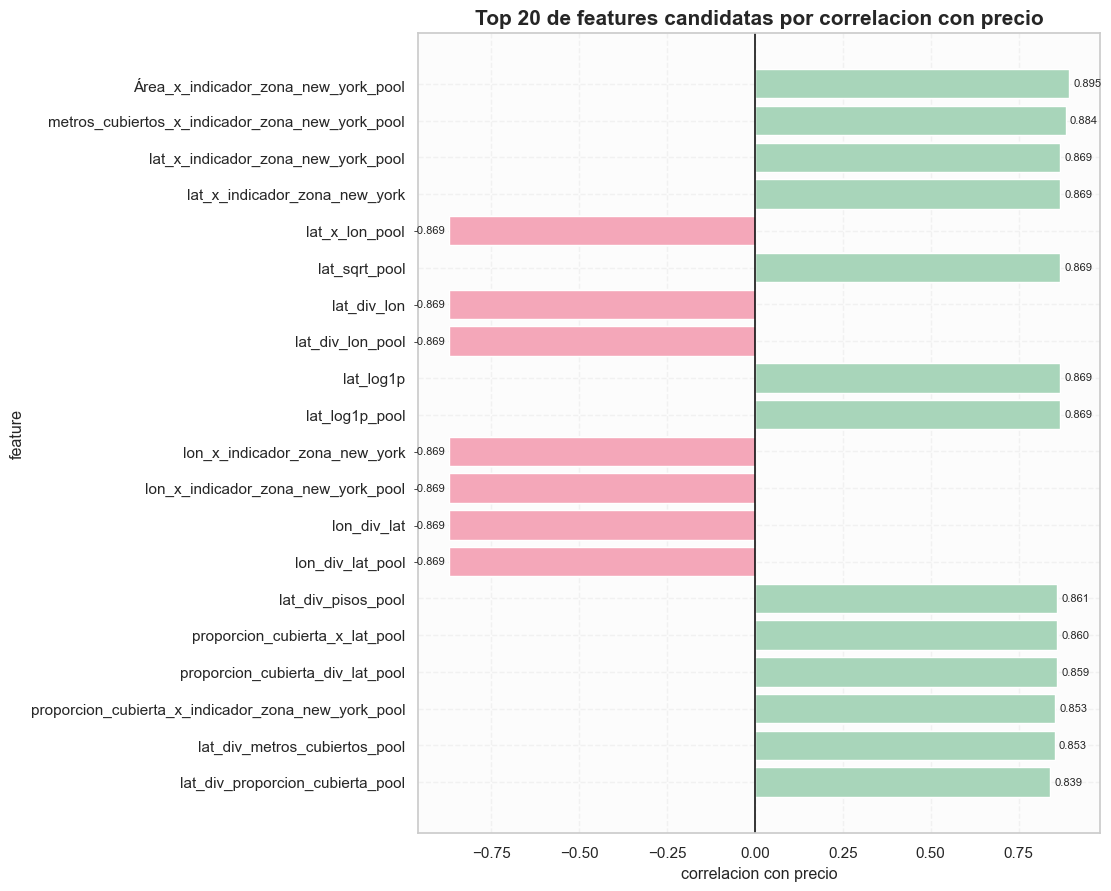

,cantidad_extras,cantidad_features_numericas,cantidad_features_diseno,RMSE_train,RMSE_validation,gap_RMSE_validation_menos_train
0,0,18,21,"32,301.2345","37,781.5428","5,480.3083"
1,4,22,25,"32,175.3981","37,425.0182","5,249.6201"
2,8,26,29,"32,079.1138","37,286.5666","5,207.4529"
3,12,30,33,"29,069.1187","34,105.3445","5,036.2259"
4,16,34,37,"28,350.7323","32,879.2669","4,528.5346"
5,24,42,45,"27,842.7289","32,713.0388","4,870.3099"
6,32,50,53,"27,659.9958","31,520.4263","3,860.4304"
7,40,58,61,"27,210.2153","31,722.6893","4,512.4740"
8,50,68,71,"26,508.6051","33,156.6917","6,648.0865"
9,60,78,81,"26,278.3838","35,087.4932","8,809.1094"


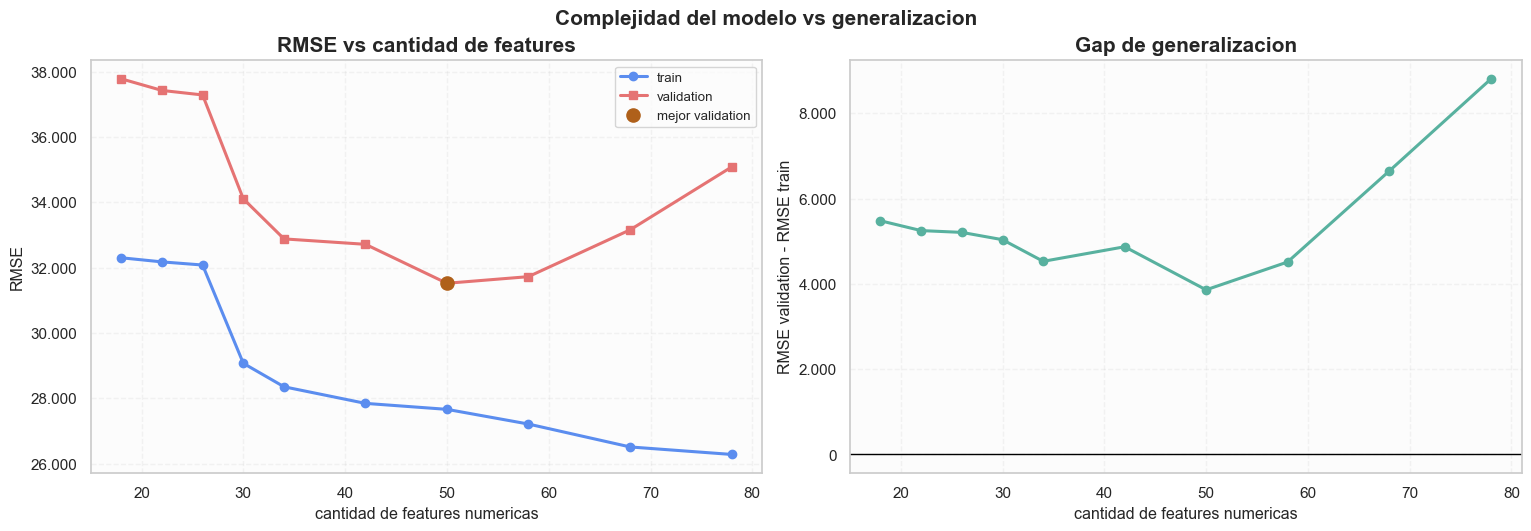

In [8]:
train_m4 = agregar_features_derivadas_m4(df_train)
validation_m4 = agregar_features_derivadas_m4(df_validation)
test_m4 = agregar_features_derivadas_m4(df_test)

train_m5 = agregar_features_derivadas_m5(df_train)
validation_m5 = agregar_features_derivadas_m5(df_validation)
test_m5 = agregar_features_derivadas_m5(df_test)

train_pool = agregar_features_candidatas_combinacionales(df_train)
validation_pool = agregar_features_candidatas_combinacionales(df_validation)

m4_num, m4_cat = obtener_configuracion_m4()
m5_num, m5_cat = obtener_configuracion_m5()

m4_arranque_num = m4_num[:18]
extras_m4 = m4_num[18:]
extras_hasta_m5 = [col for col in m5_num if col not in set(m4_num)]

ranking_candidatas = construir_ranking_features_candidatas(
    train_pool,
    columnas_base=m4_arranque_num + ["indicador_zona_new_york", "indicador_tipo_depto", "indicador_tipo_ph"],
    # Estan variables las excluyo porque son categoricas originales, no nuevas mezclas.
    columnas_excluir=["precio", "pileta", "tipo", "zona", "unidades", "categoria_edad"],
)

tabla_features_punto4 = pd.DataFrame(
    [
        {
            "modelo": "M4",
            "n_features_numericas": len(m4_num),
            "n_features_categoricas": len(m4_cat),
            "extras_para_cerrar_M4": len(extras_m4),
            "ejemplo_features_numericas": ", ".join(m4_num[:8]),
            "features_categoricas": ", ".join(m4_cat),
        },
        {
            "modelo": "M5",
            "n_features_numericas": len(m5_num),
            "n_features_categoricas": len(m5_cat),
            "nuevas_vs_M4": len(extras_hasta_m5),
            "ejemplo_features_numericas": ", ".join(m5_num[:8]),
            "features_categoricas": ", ".join(m5_cat),
        },
    ]
)
display(tabla_features_punto4)

tabla_extras_seleccionadas = pd.concat(
    [
        pd.DataFrame({"modelo": "M4", "feature_extra": extras_m4}),
        pd.DataFrame({"modelo": "M5", "feature_extra": extras_hasta_m5}),
    ],
    ignore_index=True,
)
display(tabla_extras_seleccionadas)

tabla_pool = pd.DataFrame(
    [
        {
            "features_candidatas_utiles": len(ranking_candidatas),
            "top_candidatas_evaluadas": min(20, len(ranking_candidatas)),
        }
    ]
)
display(tabla_pool)

columnas_nuevas_m4 = [col for col in train_m4.columns if col not in df_train.columns]
columnas_nuevas_m5 = [col for col in train_m5.columns if col not in df_train.columns]
print("Muestra de columnas nuevas de M4:")
display(pd.DataFrame({"feature": columnas_nuevas_m4[:15]}))
print("Muestra de columnas nuevas de M5:")
display(pd.DataFrame({"feature": columnas_nuevas_m5[:20]}))
print("Top 20 features candidatas por correlacion con el precio en train:")
display(ranking_candidatas.head(20))
fig = graficar_ranking_features_candidatas(
    ranking_candidatas,
    top_n=20,
    titulo="Top 20 de features candidatas por correlacion con precio",
)
plt.show()

equivalentes_pool_m5 = {
    "metros_cubiertos_div_lon_pool",
    f"{AREA_COL}_div_lon_pool",
    "lat_div_cubiertos_por_ambiente_pool",
    f"{AREA_COL}_x_pisos_pool",
}
extras_ordenadas_curva = extras_m4 + extras_hasta_m5 + [
    col
    for col in ranking_candidatas["feature"].tolist()
    if col not in set(m5_num) and col not in equivalentes_pool_m5
]
tabla_curva_complejidad = evaluar_curva_complejidad_features(
    df_train_modelo=train_pool,
    df_validation_modelo=validation_pool,
    columnas_base=m4_arranque_num,
    columnas_extra_ordenadas=extras_ordenadas_curva,
    columnas_categoricas=m4_cat,
    puntos_extra=[0, len(extras_m4), 8, 12, 16, 24, len(extras_m4) + len(extras_hasta_m5), 40, 50, 60],
    nombre_modelo_base="M4",
)
display(tabla_curva_complejidad)
fig = graficar_complejidad_features(
    tabla_curva_complejidad,
    titulo="Complejidad del modelo vs generalizacion",
)
plt.show()

Algo que esta muy bueno de observar es que a medida que aumento las features numericas luego de 50, los errores de train bajan rapidamente, mientras que el error en validation sube tambien. Por lo que, estamos frente al fenomeno de overfitting, ya que nos estamos "comiendo" el dataset de train con nuestras relaciones extras. El grafico de Gap ayuda tambien con la lectura de donde inicia esa separacion de errores.

### 4.2) Comparacion entre `M4` y `M5`

Entreno ambos modelos y los comparo contra `M1`, `M2` y `M3` para ver si la mejora
viene por una mejor representacion del problema o simplemente por agregar complejidad.

El barrido de complejidad de la celda anterior no define un modelo nuevo, sino
una familia de variantes que arranca en un subconjunto inicial de `M4` y va
sumando features ordenadas. Eso deja tres hitos faciles de leer:

- `25` columnas de diseno: `M4` final.
- `53` columnas de diseno: `M5` final.
- puntos por encima de `53`: extensiones del pool que ya van mas alla de `M5`.

Comparacion observada entre M1, M2, M3, M4 y M5:


,modelo,RMSE_train,RMSE_validation,gap_RMSE_validation_menos_train,R2_validation
0,M1,"77,374.6976","93,036.0457","15,661.3482",0.2266
1,M2,"77,349.7231","92,930.4505","15,580.7273",0.2284
2,M3,"43,252.1814","56,137.9689","12,885.7876",0.7184
3,M4,"32,175.3981","37,425.0182","5,249.6201",0.8749
4,M5,"27,659.9959","31,520.4264","3,860.4305",0.9112


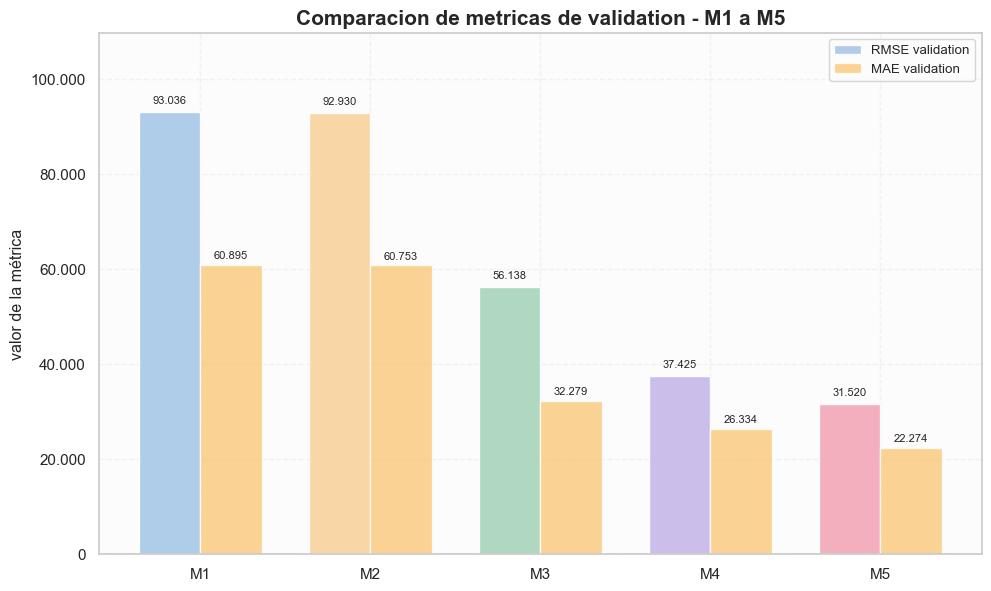

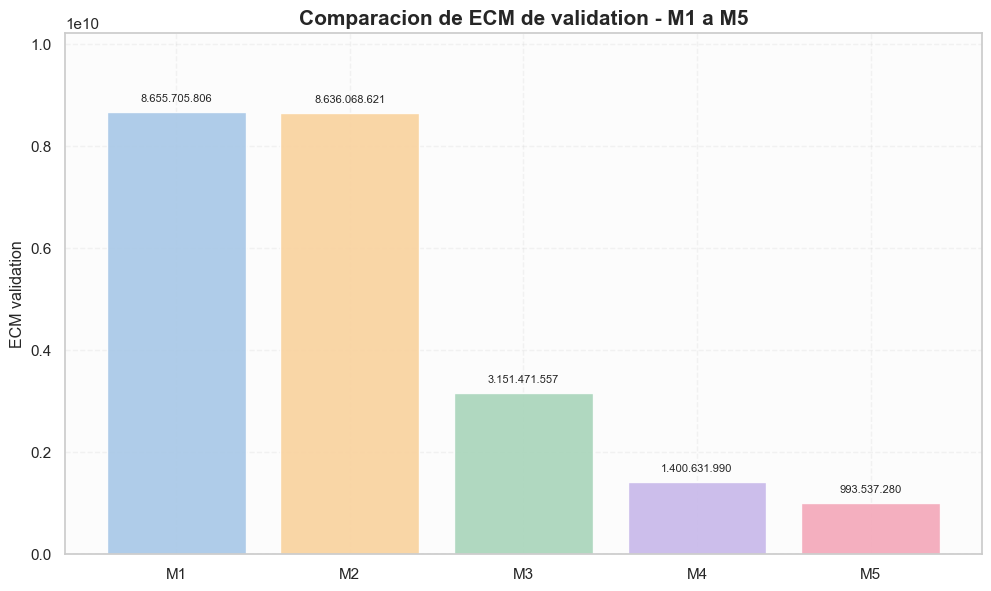

,M1,M2,M3,M4,M5
M1,0.0000,-0.1136,-65.7275,-148.5932,-195.1611
M2,0.1135,0.0000,-65.5394,-148.3110,-194.8261
M3,39.6600,39.5914,0.0000,-50.0012,-78.1003
M4,59.7736,59.7279,33.3339,0.0000,-18.7326
M5,66.1202,66.0817,43.8519,15.7771,0.0000


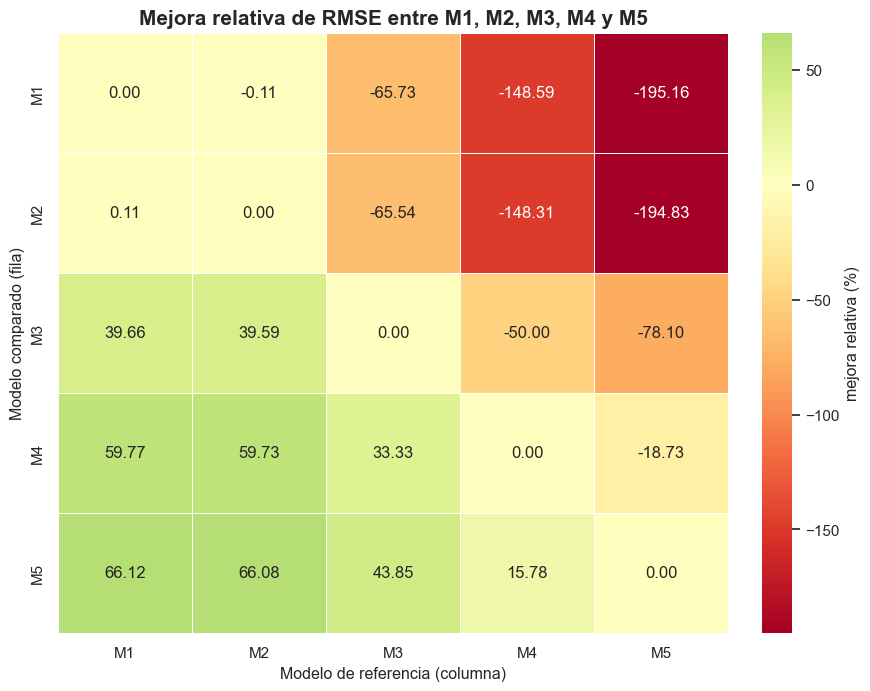

Metricas por zona para el escenario observado:


,modelo,escenario_target,zona,MAE_validation,RMSE_validation,R2_validation
0,M1,precio_observado,new_york,"66,383.9432","108,763.2577",-0.6734
1,M1,precio_observado,buenos_aires,"55,831.4396","75,681.4002",-12.5588
2,M2,precio_observado,new_york,"66,332.0804","108,543.5486",-0.6666
3,M2,precio_observado,buenos_aires,"55,605.5037","75,722.9701",-12.5737
4,M3,precio_observado,new_york,"48,526.0740","77,929.5644",0.1409
5,M3,precio_observado,buenos_aires,"17,290.3261","21,356.7384",-0.0797
6,M4,precio_observado,new_york,"39,356.4222","50,941.1528",0.6329
7,M4,precio_observado,buenos_aires,"14,320.5748","17,283.8136",0.2928
8,M5,precio_observado,new_york,"34,242.7798","42,989.6399",0.7386
9,M5,precio_observado,buenos_aires,"11,232.3358","14,322.2143",0.5144


Coeficientes mas relevantes de M4:


,feature,coeficiente,abs_coeficiente
0,lat_x_lon,"-6,766,435,166.0080","6,766,435,166.0080"
1,lon2,"-6,696,818,704.6185","6,696,818,704.6185"
2,lon,"-6,633,052,525.4016","6,633,052,525.4016"
3,lat,"-6,631,688,944.4840","6,631,688,944.4840"
...,...,...,...
11,area2,"30,108.5170","30,108.5170"
12,metros_cubiertos,"-29,262.3214","29,262.3214"
13,Área,"-17,952.6122","17,952.6122"
14,area_x_tipo_ph,"-16,532.4419","16,532.4419"


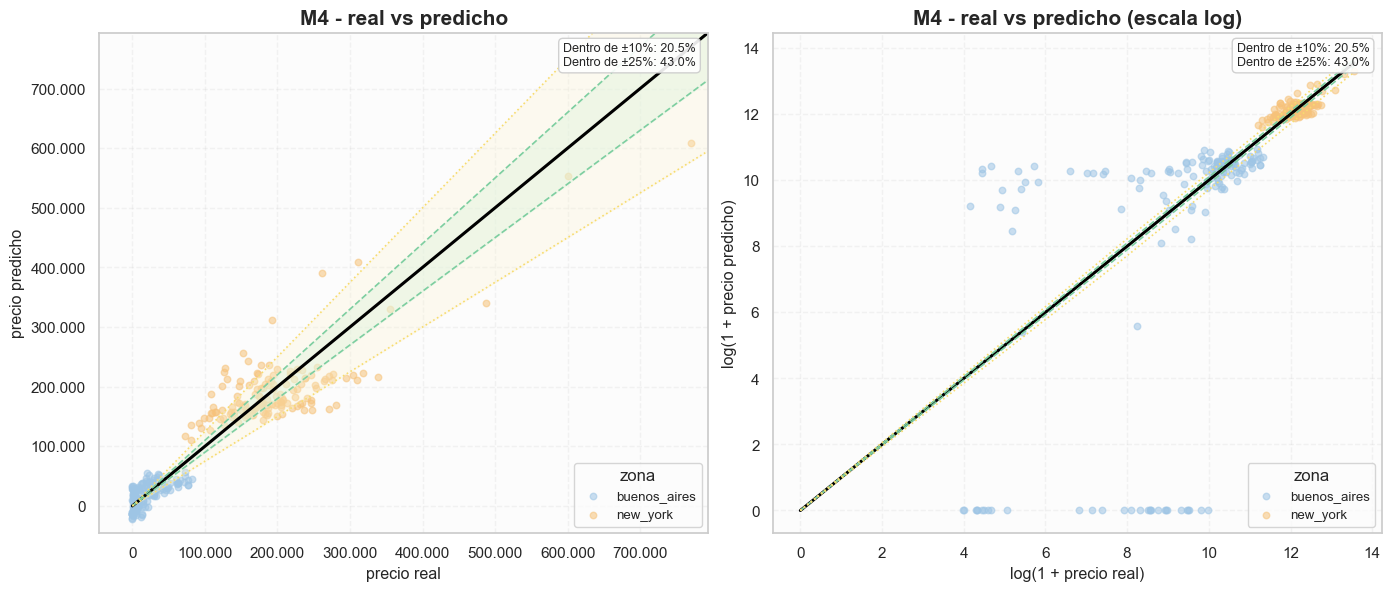

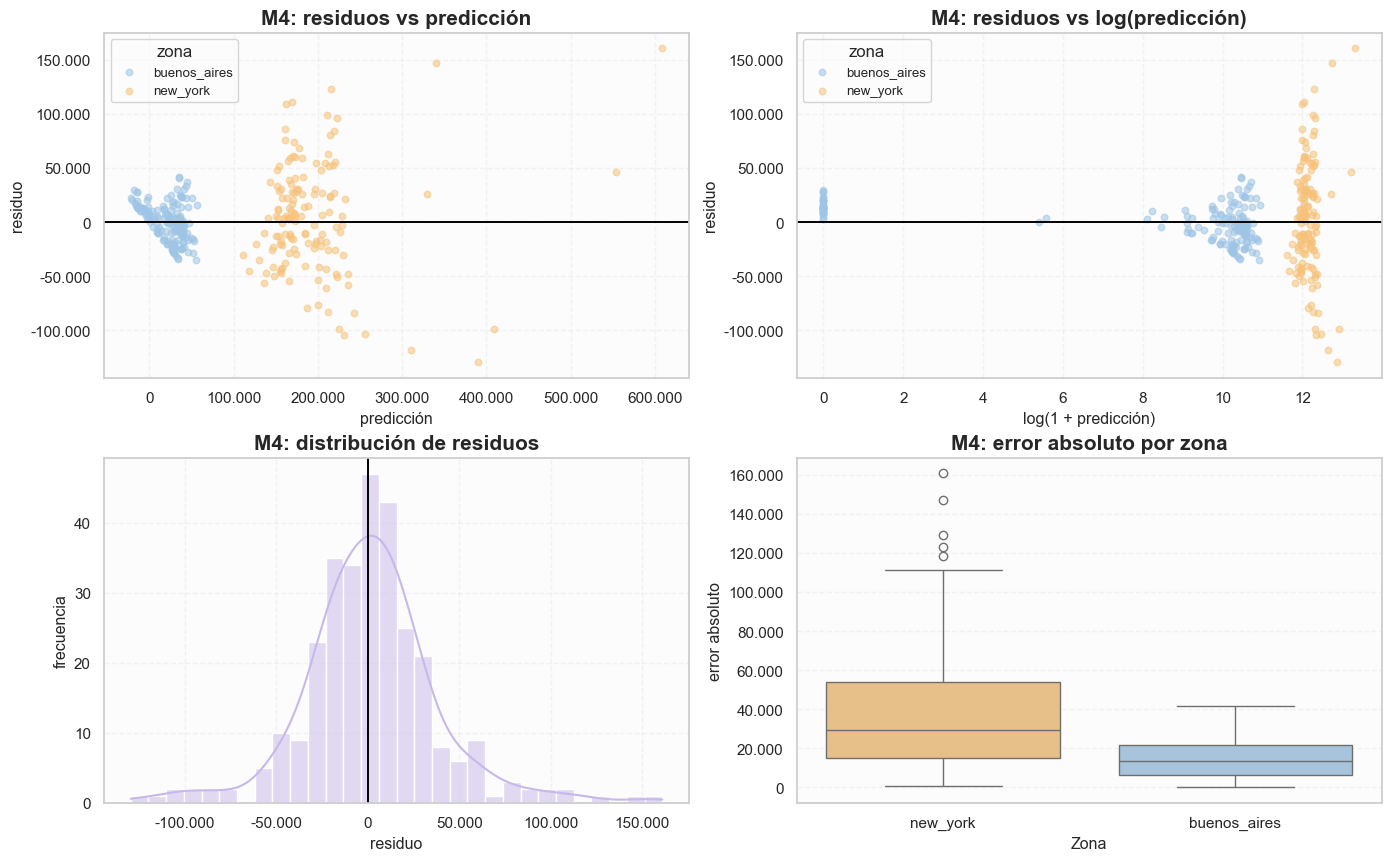

In [9]:
prep_m4 = preparar_features_para_modelo(train_m4, validation_m4, m4_num, m4_cat)
modelo_m4, pred_train_m4, pred_validation_m4, resumen_m4, metricas_zona_m4 = entrenar_y_resumir_modelo(
    "M4",
    "precio_observado",
    prep_m4["X_train"],
    train_m4["precio"],
    prep_m4["X_validation"],
    validation_m4["precio"],
    validation_m4["zona"],
)

prep_m5 = preparar_features_para_modelo(train_m5, validation_m5, m5_num, m5_cat)
modelo_m5, pred_train_m5, pred_validation_m5, resumen_m5, metricas_zona_m5 = entrenar_y_resumir_modelo(
    "M5",
    "precio_observado",
    prep_m5["X_train"],
    train_m5["precio"],
    prep_m5["X_validation"],
    validation_m5["precio"],
    validation_m5["zona"],
)

comparacion_punto4_observado = pd.DataFrame(
    [
        artefactos_base["M1"]["resumen"],
        artefactos_base["M2"]["resumen"],
        artefactos_base["M3"]["resumen"],
        resumen_m4,
        resumen_m5,
    ]
)
comparacion_punto4_observado["gap_RMSE_validation_menos_train"] = (
    comparacion_punto4_observado["RMSE_validation"] - comparacion_punto4_observado["RMSE_train"]
)

print("Comparacion observada entre M1, M2, M3, M4 y M5:")
display(
    comparacion_punto4_observado[
        ["modelo", "RMSE_train", "RMSE_validation", "gap_RMSE_validation_menos_train", "R2_validation"]
    ]
)
fig = graficar_comparacion_metricas(
    comparacion_punto4_observado,
    titulo="Comparacion de metricas de validation - M1 a M5",
)
plt.show()
fig = graficar_comparacion_ecm(
    comparacion_punto4_observado,
    titulo="Comparacion de ECM de validation - M1 a M5",
)
plt.show()

matriz_mejora_global = construir_matriz_mejora_relativa(
    comparacion_punto4_observado,
    columna_metrica="RMSE_validation",
    escenario="precio_observado",
    orden_modelos=["M1", "M2", "M3", "M4", "M5"],
)
display(matriz_mejora_global)
fig = graficar_matriz_mejora_relativa(
    matriz_mejora_global,
    titulo="Mejora relativa de RMSE entre M1, M2, M3, M4 y M5",
)
plt.show()

metricas_por_zona_punto4 = pd.concat(
    [
        artefactos_base["M1"]["metricas_zona"],
        artefactos_base["M2"]["metricas_zona"],
        artefactos_base["M3"]["metricas_zona"],
        metricas_zona_m4,
        metricas_zona_m5,
    ],
    ignore_index=True,
)
print("Metricas por zona para el escenario observado:")
display(metricas_por_zona_punto4)

print("Coeficientes mas relevantes de M4:")
display(modelo_m4.tabla_coeficientes().head(15))
fig = graficar_real_vs_predicho_panel(
    validation_m4["precio"],
    pred_validation_m4,
    zona=validation_m4["zona"],
    titulo="M4 - real vs predicho",
)
plt.show()
fig = graficar_residuos_panel(
    validation_m4["precio"],
    pred_validation_m4,
    zona=validation_m4["zona"],
    titulo_base="M4",
)
plt.show()


### 4.3) Respuesta al enunciado

Esperaba que agregar variables derivadas ayudara hasta cierto punto y que, despues de eso, empezara a aparecer sobreajuste.
Eso es lo que se ve al comparar train contra validation: al principio sumar features ayuda, pero cuando el modelo crece demasiado la mejora deja de ser clara.
Por eso use `validation` para decidir hasta donde convenia complejizar el modelo.


## 5. Regularizacion

### 5.1) Incorporacion de `L2` y `L1` en `RegresionLineal`

En esta parte trabajo sobre `M4`.
Agregue regularizacion `L2` para Ridge y `L1` para Lasso dentro de la misma clase `RegresionLineal`.


In [10]:
matrices_m4 = preparar_matrices_para_modelado(
    train_df=train_m4,
    validation_df=validation_m4,
    test_df=test_m4,
    columnas_numericas=m4_num,
    columnas_categoricas=m4_cat,
    columna_target="precio",
)
matrices_m5 = preparar_matrices_para_modelado(
    train_df=train_m5,
    validation_df=validation_m5,
    test_df=test_m5,
    columnas_numericas=m5_num,
    columnas_categoricas=m5_cat,
    columna_target="precio",
)

X_train_m4 = matrices_m4["X_train"]
X_validation_m4 = matrices_m4["X_validation"]
X_test_m4 = matrices_m4["X_test"]
y_train_m4 = matrices_m4["y_train"]
y_validation_m4 = matrices_m4["y_validation"]

dataset_inspeccion = exportar_csv_inspeccion_modelos(
    PROCESSED_DIR / "dataset_inspeccion_modelos.csv",
    splits=[
        {
            "split_name": "train",
            "dataframe_original": df_train,
            "modelos": {
                "m4": {
                    "engineered_df": train_m4,
                    "scaled_df": matrices_m4["X_train_numerico_escalado"],
                    "dummy_df": matrices_m4["X_train_categorico"],
                    "design_df": matrices_m4["X_train"],
                },
                "m5": {
                    "engineered_df": train_m5,
                    "scaled_df": matrices_m5["X_train_numerico_escalado"],
                    "dummy_df": matrices_m5["X_train_categorico"],
                    "design_df": matrices_m5["X_train"],
                },
            },
        },
        {
            "split_name": "validation",
            "dataframe_original": df_validation,
            "modelos": {
                "m4": {
                    "engineered_df": validation_m4,
                    "scaled_df": matrices_m4["X_validation_numerico_escalado"],
                    "dummy_df": matrices_m4["X_validation_categorico"],
                    "design_df": matrices_m4["X_validation"],
                },
                "m5": {
                    "engineered_df": validation_m5,
                    "scaled_df": matrices_m5["X_validation_numerico_escalado"],
                    "dummy_df": matrices_m5["X_validation_categorico"],
                    "design_df": matrices_m5["X_validation"],
                },
            },
        },
        {
            "split_name": "test",
            "dataframe_original": df_test,
            "modelos": {
                "m4": {
                    "engineered_df": test_m4,
                    "scaled_df": matrices_m4["X_test_numerico_escalado"],
                    "dummy_df": matrices_m4["X_test_categorico"],
                    "design_df": matrices_m4["X_test"],
                },
                "m5": {
                    "engineered_df": test_m5,
                    "scaled_df": matrices_m5["X_test_numerico_escalado"],
                    "dummy_df": matrices_m5["X_test_categorico"],
                    "design_df": matrices_m5["X_test"],
                },
            },
        },
    ],
)

print("Dimensiones M4 para regularizacion:")
print("X_train_m4:", X_train_m4.shape)
print("X_validation_m4:", X_validation_m4.shape)
print("X_test_m4:", X_test_m4.shape)
print("CSV unico de inspeccion exportado en:", PROCESSED_DIR / "dataset_inspeccion_modelos.csv")
print("Vista rapida del CSV de inspeccion:")
display(dataset_inspeccion.iloc[:5, :15])


Dimensiones M4 para regularizacion:
X_train_m4: (1190, 25)
X_validation_m4: (298, 25)
X_test_m4: (372, 25)
CSV unico de inspeccion exportado en: C:\Users\tomas\OneDrive\Documentos\1. Udesa-TG\Machine Learning y Deep Learning\Gonzalez_Tomas_TP1\data\processed\dataset_inspeccion_modelos.csv
Vista rapida del CSV de inspeccion:


,split,precio,tipo,Área,metros_cubiertos,unidades,ambientes,pisos,pileta,lat,lon,edad,zona,superficie_descubierta,proporcion_cubierta
0,train,"199,158.5556",depto,69.8742,69.5620,m2,6,3.0000,False,40.7334,-73.9445,12.3028,new_york,0.3122,0.9955
1,train,"162,883.3262",depto,73.8503,73.3928,m2,3,3.0000,False,40.7361,-73.9250,11.8741,new_york,0.4575,0.9938
2,train,"97,739.5363",depto,70.5422,67.3334,m2,4,3.0000,False,40.7519,-73.9144,8.2231,new_york,3.2088,0.9545
3,train,"120,202.1659",depto,75.5716,74.0148,m2,10,3.0000,False,40.6650,-73.9862,8.2038,new_york,1.5568,0.9794
4,train,64.3820,depto,79.0437,75.4725,m2,9,3.0000,False,-34.8146,-58.2713,9.5471,buenos_aires,3.5712,0.9548


In [11]:
tabla_parametros_modelo = pd.DataFrame(
    [
        {"modelo": "sin_regularizacion", "l1": 0.0, "l2": 0.0},
        {"modelo": "ridge_demo", "l1": 0.0, "l2": 1.0},
        {"modelo": "lasso_demo", "l1": 1.0, "l2": 0.0},
    ]
)
display(tabla_parametros_modelo)


,modelo,l1,l2
0,sin_regularizacion,0.0000,0.0000
1,ridge_demo,0.0000,1.0000
2,lasso_demo,1.0000,0.0000


### 5.2) Trayectoria de coeficientes con Ridge

Para que la trayectoria se vea completa, uso una grilla mas densa y la extiendo hasta `10^4`.
Eso permite ver mejor cuando los coeficientes empiezan a comprimirse y si el encogimiento es suave
o abrupto.


,lambda_trayectoria_ridge,lambda_trayectoria_lasso,lambda_cv_ridge,lambda_cv_lasso
0,0.0000,0.0001,0.0000,0.0001
1,0.0000,0.0003,0.0000,0.0005
2,0.0000,0.0008,0.0000,0.0022
3,0.0000,0.0022,0.0003,0.0100
...,...,...,...,...
15,215.4435,464.1589,NaN,NaN
16,774.2637,"1,291.5497",NaN,NaN
17,"2,782.5594","3,593.8137",NaN,NaN
18,"10,000.0000","10,000.0000",NaN,NaN


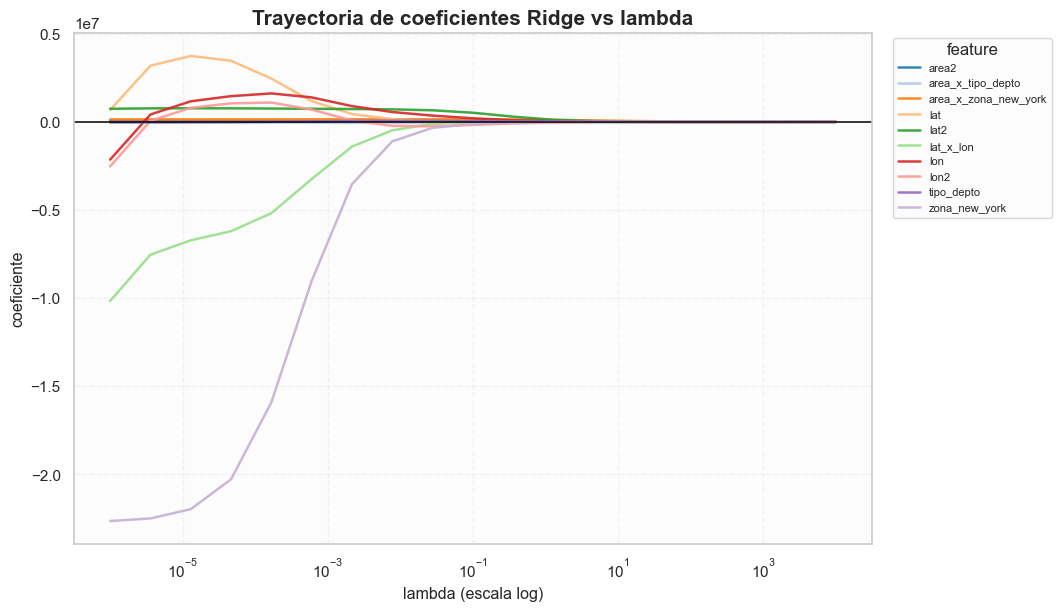

In [12]:
lambdas_trayectoria_ridge = np.logspace(-6, 4, 19)
lambdas_trayectoria_lasso = np.logspace(-4, 4, 19)
lambdas_cv_ridge = np.logspace(-6, 4, 13)
lambdas_cv_lasso = np.logspace(-4, 4, 13)
learning_rate_lasso = 0.01
max_iteraciones_lasso = 20000
tolerancia_lasso = 1e-6

tabla_grillas_lambda = pd.DataFrame(
    {
        "lambda_trayectoria_ridge": pd.Series(lambdas_trayectoria_ridge),
        "lambda_trayectoria_lasso": pd.Series(lambdas_trayectoria_lasso),
        "lambda_cv_ridge": pd.Series(lambdas_cv_ridge),
        "lambda_cv_lasso": pd.Series(lambdas_cv_lasso),
    }
)
display(tabla_grillas_lambda)

trayectoria_ridge = construir_regularization_path(
    X_train=X_train_m4.values,
    y_train=y_train_m4.values,
    feature_names=X_train_m4.columns.tolist(),
    lambdas=lambdas_trayectoria_ridge,
    tipo_regularizacion="ridge",
)
fig = graficar_regularization_paths(
    trayectoria_ridge,
    titulo="Trayectoria de coeficientes Ridge vs lambda",
    top_n=10,
)
plt.show()


En Ridge no esperaba que todas las trayectorias fueran perfectamente monotonicas.
Con variables correlacionadas, algunos pesos se redistribuyen antes de achicarse.


### 5.3) Trayectoria de coeficientes con Lasso y comparacion con Ridge

En Lasso el interes no esta solo en achicar coeficientes, sino tambien en ver cuando empiezan
a aparecer ceros. Por eso uso un rango amplio de `lambda`, nuevamente hasta `10^4`.


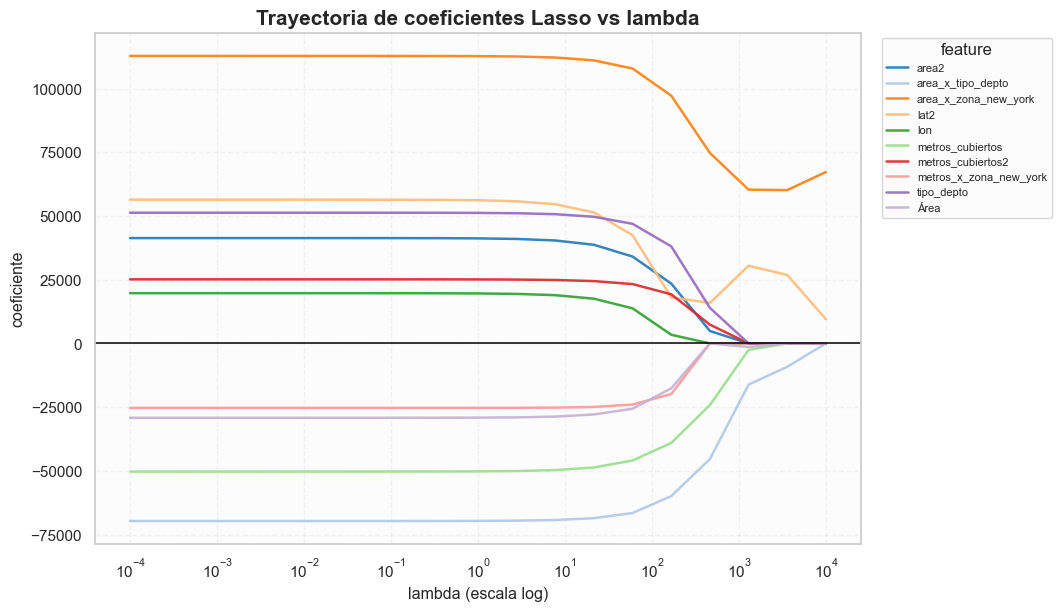

In [13]:
trayectoria_lasso = construir_regularization_path(
    X_train=X_train_m4.values,
    y_train=y_train_m4.values,
    feature_names=X_train_m4.columns.tolist(),
    lambdas=lambdas_trayectoria_lasso,
    tipo_regularizacion="lasso",
    learning_rate=learning_rate_lasso,
    max_iteraciones=max_iteraciones_lasso,
    tolerancia=tolerancia_lasso,
)
fig = graficar_regularization_paths(
    trayectoria_lasso,
    titulo="Trayectoria de coeficientes Lasso vs lambda",
    top_n=10,
)
plt.show()


Comparado con Ridge, Lasso achica mas fuerte varios coeficientes y termina anulando algunos.
En Ridge, como las variables ya estan escaladas, alcanza un `lambda` chico para que la penalizacion empiece a mover la solucion.


### 5.4) Seleccion de `lambda` por validacion cruzada y definicion de `M6`

Para elegir `lambda` mire el ECM de validacion cruzada y despues contraste con RMSE, MAE y R2.
La idea fue no quedarme solo con una metrica antes de definir `M6`.


Resultados de validacion cruzada para Ridge:


,lambda,ECM_promedio_cv,ECM_std_cv,coeficientes_casi_cero_promedio
0,0.0000,"1,187,347,104.7474","281,932,974.8601",0.0000
1,0.0000,"1,187,669,143.3678","280,256,346.6488",0.0000
2,0.0000,"1,191,923,166.5604","270,830,841.6339",0.0000
3,0.0003,"1,242,309,707.4354","244,967,453.0137",0.0000
...,...,...,...,...
9,31.6228,"1,645,710,853.7809","224,940,789.1124",0.0000
10,215.4435,"1,726,836,367.4749","224,147,491.7583",0.0000
11,"1,467.7993","2,052,477,619.7463","249,055,197.8340",0.0000
12,"10,000.0000","3,859,379,192.5191","320,514,661.5120",0.0000


Resultados de validacion cruzada para Lasso:


,lambda,ECM_promedio_cv,ECM_std_cv,coeficientes_casi_cero_promedio
0,0.0001,"1,503,170,345.5348","225,942,186.3784",0.0000
1,0.0005,"1,503,170,366.7246","225,942,201.1444",0.0000
2,0.0022,"1,503,170,465.0815","225,942,269.6803",0.0000
3,0.0100,"1,503,170,921.6187","225,942,587.7787",0.0000
...,...,...,...,...
9,100.0000,"1,511,378,571.8219","229,089,274.5936",2.8000
10,464.1589,"1,563,957,429.5919","241,350,199.8212",10.0000
11,"2,154.4347","1,649,142,602.4226","255,657,007.3298",18.6000
12,"10,000.0000","1,809,900,451.0648","292,016,317.1313",22.0000


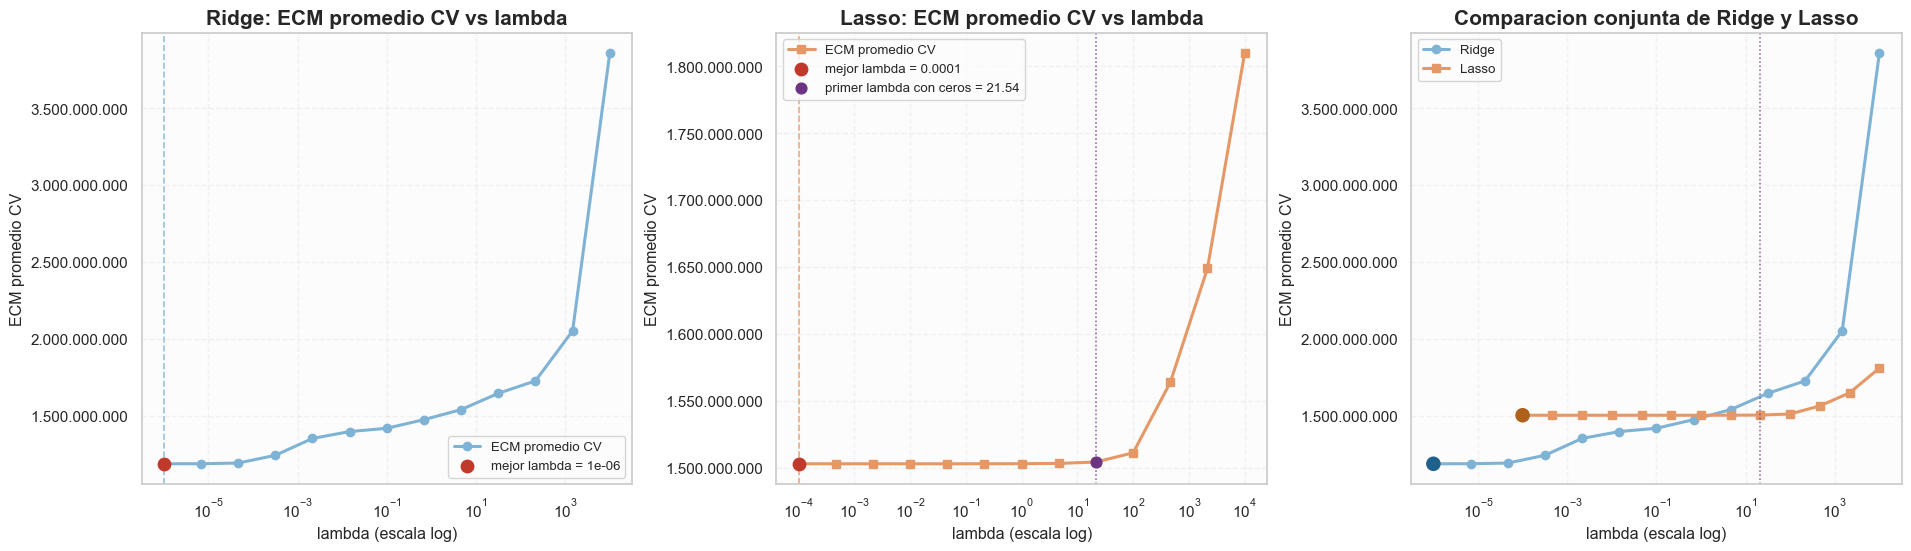

Metricas de validation segun lambda:


,tipo_regularizacion,lambda,RMSE_validation,MAE_validation,R2_validation,cantidad_coeficientes_casi_cero
0,ridge,0.0000,"38,392.8660","26,619.2693",0.8683,0
1,ridge,0.0000,"38,380.7822","26,619.2026",0.8684,0
2,ridge,0.0000,"38,338.1220","26,617.6942",0.8687,0
3,ridge,0.0000,"38,216.7067","26,638.4492",0.8695,0
...,...,...,...,...,...,...
34,lasso,464.1589,"44,472.1573","29,627.6879",0.8233,11
35,lasso,"1,291.5497","46,350.8047","29,401.9271",0.8080,16
36,lasso,"3,593.8137","47,192.4274","29,488.0945",0.8010,20
37,lasso,"10,000.0000","49,093.4938","32,675.6929",0.7847,22


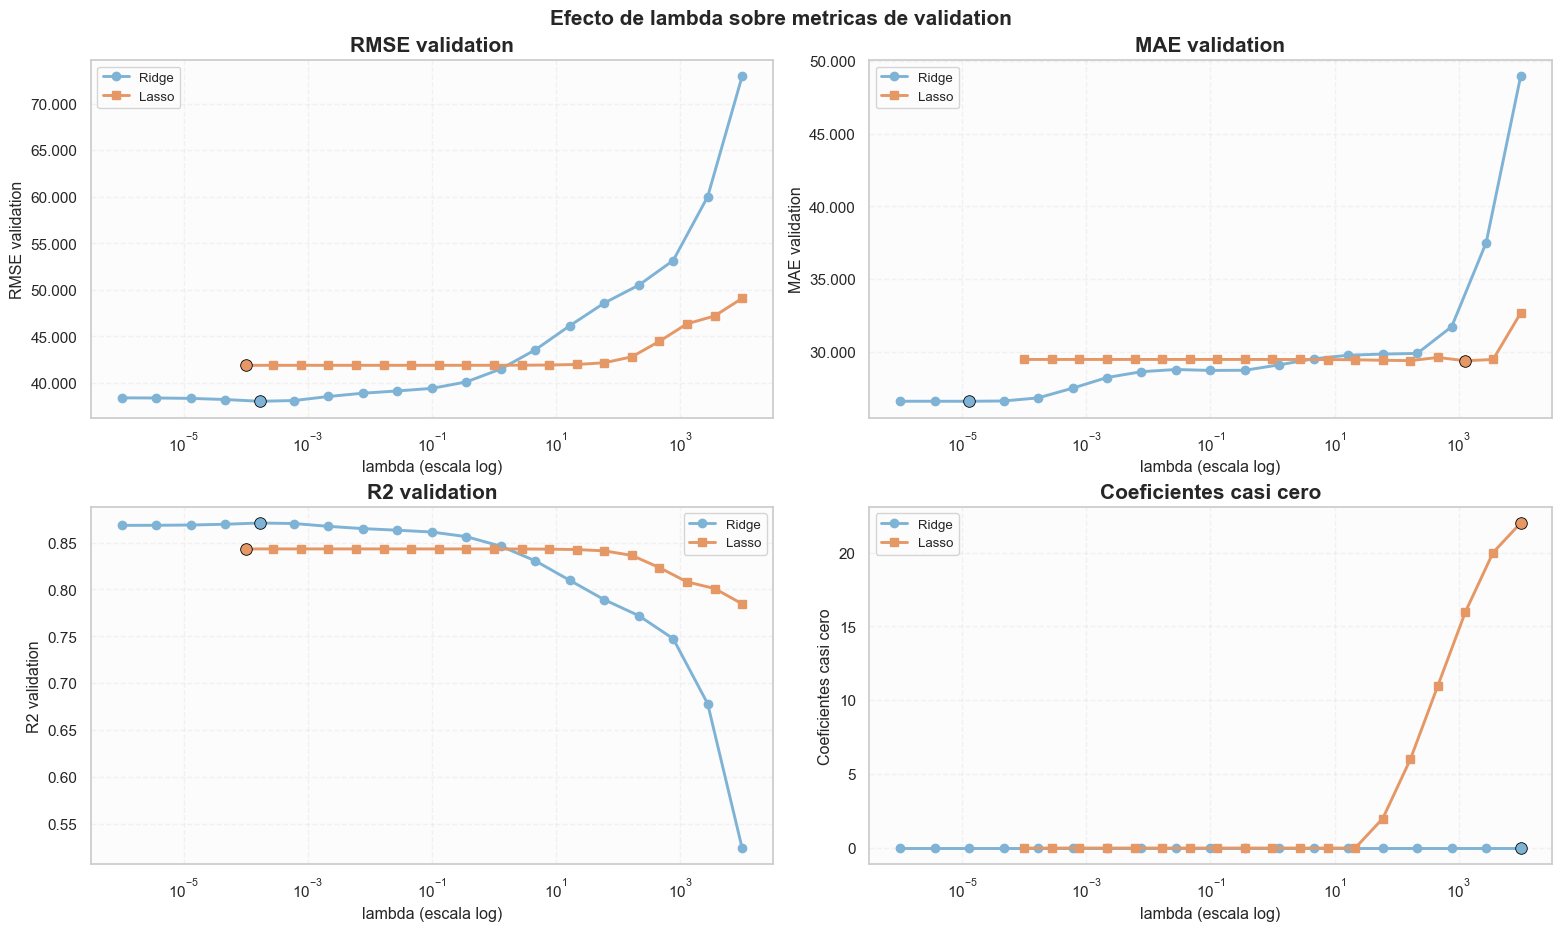

In [14]:
tabla_cv_ridge = cross_validate_lambdas_con_preprocesamiento(
    dataframe_modelo=train_m4,
    columnas_numericas=m4_num,
    columnas_categoricas=m4_cat,
    lambdas=lambdas_cv_ridge,
    tipo_regularizacion="ridge",
    n_splits=5,
    seed=42,
)
tabla_cv_lasso = cross_validate_lambdas_con_preprocesamiento(
    dataframe_modelo=train_m4,
    columnas_numericas=m4_num,
    columnas_categoricas=m4_cat,
    lambdas=lambdas_cv_lasso,
    tipo_regularizacion="lasso",
    n_splits=5,
    seed=42,
    learning_rate=learning_rate_lasso,
    max_iteraciones=max_iteraciones_lasso,
    tolerancia=tolerancia_lasso,
)

print("Resultados de validacion cruzada para Ridge:")
display(tabla_cv_ridge[["lambda", "ECM_promedio_cv", "ECM_std_cv", "coeficientes_casi_cero_promedio"]])
print("Resultados de validacion cruzada para Lasso:")
display(tabla_cv_lasso[["lambda", "ECM_promedio_cv", "ECM_std_cv", "coeficientes_casi_cero_promedio"]])

fig = graficar_panel_cv_regularizacion(tabla_cv_ridge, tabla_cv_lasso)
plt.show()

mejor_lambda_ridge = float(tabla_cv_ridge.loc[tabla_cv_ridge["ECM_promedio_cv"].idxmin(), "lambda"])
mejor_lambda_lasso = float(tabla_cv_lasso.loc[tabla_cv_lasso["ECM_promedio_cv"].idxmin(), "lambda"])
tabla_lasso_sparsity = tabla_cv_lasso[tabla_cv_lasso["coeficientes_casi_cero_promedio"] > 0].copy()
lambda_inicio_sparsity_lasso = (
    float(tabla_lasso_sparsity.iloc[0]["lambda"]) if not tabla_lasso_sparsity.empty else np.nan
)

tabla_metricas_lambda_ridge = evaluar_metricas_regularizacion_en_grilla(
    X_train=X_train_m4.values,
    y_train=y_train_m4.values,
    X_validation=X_validation_m4.values,
    y_validation=y_validation_m4.values,
    feature_names=X_train_m4.columns.tolist(),
    lambdas=lambdas_trayectoria_ridge,
    tipo_regularizacion="ridge",
)
tabla_metricas_lambda_lasso = evaluar_metricas_regularizacion_en_grilla(
    X_train=X_train_m4.values,
    y_train=y_train_m4.values,
    X_validation=X_validation_m4.values,
    y_validation=y_validation_m4.values,
    feature_names=X_train_m4.columns.tolist(),
    lambdas=lambdas_trayectoria_lasso,
    tipo_regularizacion="lasso",
    learning_rate=learning_rate_lasso,
    max_iteraciones=max_iteraciones_lasso,
    tolerancia=tolerancia_lasso,
)
tabla_metricas_lambda = pd.concat(
    [tabla_metricas_lambda_ridge, tabla_metricas_lambda_lasso],
    ignore_index=True,
)

print("Metricas de validation segun lambda:")
display(
    tabla_metricas_lambda[
        [
            "tipo_regularizacion",
            "lambda",
            "RMSE_validation",
            "MAE_validation",
            "R2_validation",
            "cantidad_coeficientes_casi_cero",
        ]
    ]
)

fig = graficar_metricas_regularizacion_vs_lambda(
    tabla_metricas_lambda,
    metricas=["RMSE_validation", "MAE_validation", "R2_validation", "cantidad_coeficientes_casi_cero"],
    titulo="Efecto de lambda sobre metricas de validation",
)
plt.show()




,regularizacion,mejor_lambda_cv,lambda_inicio_sparsity
0,Ridge,0.0000,NaN
1,Lasso,0.0001,21.5443


,modelo,tipo_regularizacion,lambda,ECM_validation,MAE_validation,RMSE_validation,R2_validation,cantidad_coeficientes_casi_cero
0,M4,sin_regularizacion,0.0000,"1,400,631,989.8224","26,334.4210","37,425.0182",0.8749,0
1,Ridge,ridge,0.0000,"1,474,012,158.0846","26,619.2693","38,392.8660",0.8683,0
2,Lasso,lasso,0.0001,"1,755,008,596.9453","29,491.2670","41,892.8227",0.8432,0


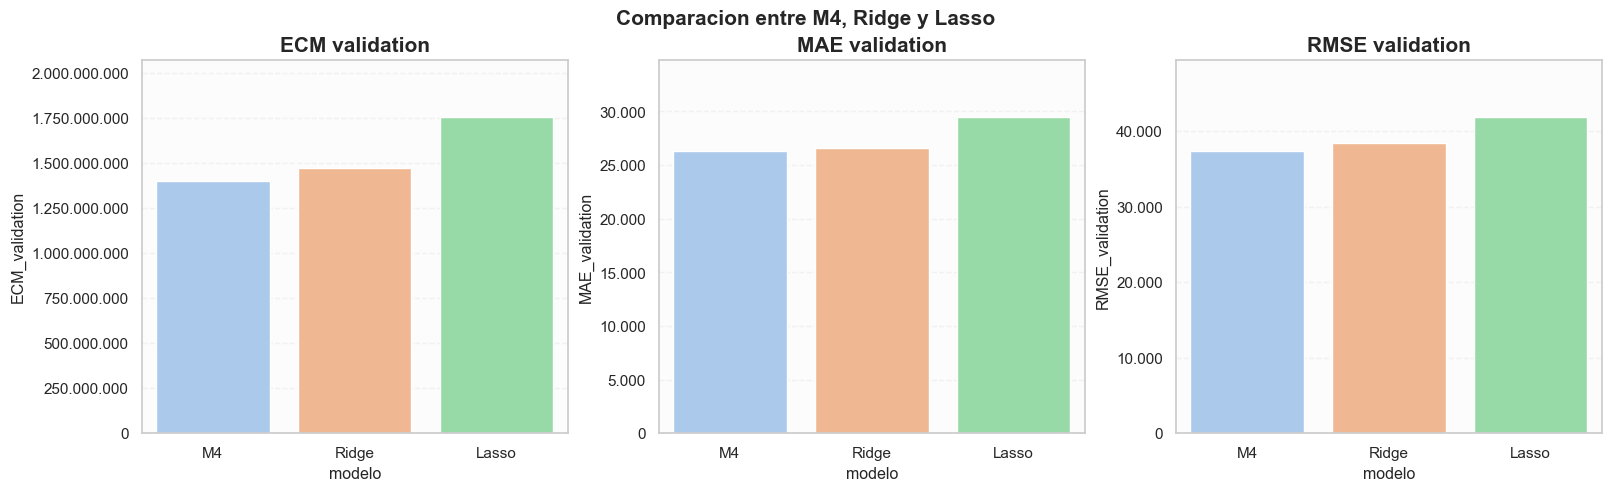

,modelo,regularizacion,lambda,tipo_regularizacion,ECM_train,MAE_train,RMSE_train,R2_train,ECM_validation,MAE_validation,RMSE_validation,R2_validation,cantidad_coeficientes_casi_cero
0,M6,Ridge,0.0000,ridge,"1,115,152,226.9170","22,265.5219","33,393.8951",0.8738,"1,474,012,158.0846","26,619.2693","38,392.8660",0.8683,0


In [15]:
mejor_lambda_ridge = float(tabla_cv_ridge.loc[tabla_cv_ridge["ECM_promedio_cv"].idxmin(), "lambda"])
mejor_lambda_lasso = float(tabla_cv_lasso.loc[tabla_cv_lasso["ECM_promedio_cv"].idxmin(), "lambda"])

modelo_m4_sin_regularizacion = RegresionLineal(
    X_train_m4.values,
    y_train_m4.values,
    feature_names=X_train_m4.columns.tolist(),
)
modelo_m4_sin_regularizacion.fit_pseudoinverse()
pred_validation_m4 = modelo_m4_sin_regularizacion.predict(X_validation_m4.values)
resumen_m4_sin_regularizacion = {
    "modelo": "M4",
    "tipo_regularizacion": "sin_regularizacion",
    "lambda": 0.0,
    **{f"{k}_validation": v for k, v in resumir_metricas_regresion(y_validation_m4.values, pred_validation_m4).items()},
    "cantidad_coeficientes_casi_cero": modelo_m4_sin_regularizacion.contar_coeficientes_casi_cero(tolerancia=1e-4),
}

modelo_ridge_final, resumen_ridge_final = entrenar_modelo_regularizado_y_evaluar(
    X_train=X_train_m4.values,
    y_train=y_train_m4.values,
    X_validation=X_validation_m4.values,
    y_validation=y_validation_m4.values,
    feature_names=X_train_m4.columns.tolist(),
    tipo_regularizacion="ridge",
    lambda_reg=mejor_lambda_ridge,
)
modelo_lasso_final, resumen_lasso_final = entrenar_modelo_regularizado_y_evaluar(
    X_train=X_train_m4.values,
    y_train=y_train_m4.values,
    X_validation=X_validation_m4.values,
    y_validation=y_validation_m4.values,
    feature_names=X_train_m4.columns.tolist(),
    tipo_regularizacion="lasso",
    lambda_reg=mejor_lambda_lasso,
    learning_rate=learning_rate_lasso,
    max_iteraciones=max_iteraciones_lasso,
    tolerancia=tolerancia_lasso,
)

comparacion_regularizados = pd.DataFrame(
    [
        resumen_m4_sin_regularizacion,
        {"modelo": "Ridge", **resumen_ridge_final},
        {"modelo": "Lasso", **resumen_lasso_final},
    ]
)
tabla_resumen_lambdas = pd.DataFrame(
    [
        {
            "regularizacion": "Ridge",
            "mejor_lambda_cv": mejor_lambda_ridge,
            "lambda_inicio_sparsity": np.nan,
        },
        {
            "regularizacion": "Lasso",
            "mejor_lambda_cv": mejor_lambda_lasso,
            "lambda_inicio_sparsity": lambda_inicio_sparsity_lasso,
        },
    ]
)
display(tabla_resumen_lambdas)
display(
    comparacion_regularizados[
        [
            "modelo",
            "tipo_regularizacion",
            "lambda",
            "ECM_validation",
            "MAE_validation",
            "RMSE_validation",
            "R2_validation",
            "cantidad_coeficientes_casi_cero",
        ]
    ]
)
fig = graficar_metricas_validacion(
    comparacion_regularizados,
    titulo="Comparacion entre M4, Ridge y Lasso",
)
plt.show()

if resumen_ridge_final["ECM_validation"] <= resumen_lasso_final["ECM_validation"]:
    nombre_m6 = "Ridge"
    lambda_m6 = mejor_lambda_ridge
    resumen_m6 = resumen_ridge_final
else:
    nombre_m6 = "Lasso"
    lambda_m6 = mejor_lambda_lasso
    resumen_m6 = resumen_lasso_final

display(pd.DataFrame([{"modelo": "M6", "regularizacion": nombre_m6, "lambda": lambda_m6, **resumen_m6}]))

La lectura general de esta parte es bastante directa: Ridge queda muy cerca de OLS cuando el mejor `lambda` sale chico, y Lasso recorta mas, pero puede sumar sesgo antes de mejorar validation.
En este TP, `M4` ya venia bastante filtrado, asi que el margen de mejora por regularizacion no era tan grande.


Con los `lambda` elegidos, comparo tambien los coeficientes mas grandes y mas chicos de Ridge y Lasso para cerrar el punto.


10 coeficientes mas importantes de Ridge:


,feature,coeficiente,abs_coeficiente
0,zona_new_york,"-22,648,536.3535","22,648,536.3535"
1,lat_x_lon,"-10,159,998.7133","10,159,998.7133"
2,lon2,"-2,524,797.7192","2,524,797.7192"
3,lon,"-2,141,207.6097","2,141,207.6097"
4,lat2,"743,148.0633","743,148.0633"
5,lat,"679,384.7243","679,384.7243"
6,area_x_zona_new_york,"141,416.1656","141,416.1656"
7,area2,"62,724.0632","62,724.0632"
8,metros_x_zona_new_york,"-49,572.1599","49,572.1599"
9,metros_cubiertos,"-40,974.5585","40,974.5585"


10 coeficientes menos importantes de Ridge:


,feature,coeficiente,abs_coeficiente
0,metros_cubiertos2,"10,258.4931","10,258.4931"
1,edad,"9,387.3531","9,387.3531"
2,area_x_tipo_ph,"-8,977.5530","8,977.5530"
3,edad_x_zona_new_york,"-6,404.2469","6,404.2469"
4,ambientes_x_zona_new_york,"3,321.8922","3,321.8922"
5,edad2,"-2,472.5645","2,472.5645"
6,tipo_ph,"1,292.0465","1,292.0465"
7,cubiertos_por_ambiente,473.8871,473.8871
8,area_por_ambiente,381.7393,381.7393
9,ambientes,-300.6417,300.6417


10 coeficientes mas importantes de Lasso:


,feature,coeficiente,abs_coeficiente
0,area_x_zona_new_york,"112,800.4028","112,800.4028"
1,area_x_tipo_depto,"-69,699.0837","69,699.0837"
2,lat2,"56,405.8405","56,405.8405"
3,tipo_depto,"51,279.0482","51,279.0482"
4,metros_cubiertos,"-50,288.4882","50,288.4882"
5,area2,"41,333.5001","41,333.5001"
6,Área,"-29,183.7161","29,183.7161"
7,metros_x_zona_new_york,"-25,300.2385","25,300.2385"
8,metros_cubiertos2,"25,139.0790","25,139.0790"
9,lon,"19,707.3341","19,707.3341"


10 coeficientes menos importantes de Lasso:


,feature,coeficiente,abs_coeficiente
0,tipo_ph,"11,154.0877","11,154.0877"
1,area_x_tipo_ph,"-10,573.2602","10,573.2602"
2,edad,"7,622.7660","7,622.7660"
3,superficie_descubierta,"-7,437.7757","7,437.7757"
4,ambientes_x_zona_new_york,"4,792.1127","4,792.1127"
5,edad_x_zona_new_york,"-4,330.9725","4,330.9725"
6,ambientes,"-1,971.6331","1,971.6331"
7,edad2,-923.0328,923.0328
8,cubiertos_por_ambiente,-375.6273,375.6273
9,area_por_ambiente,-196.5331,196.5331


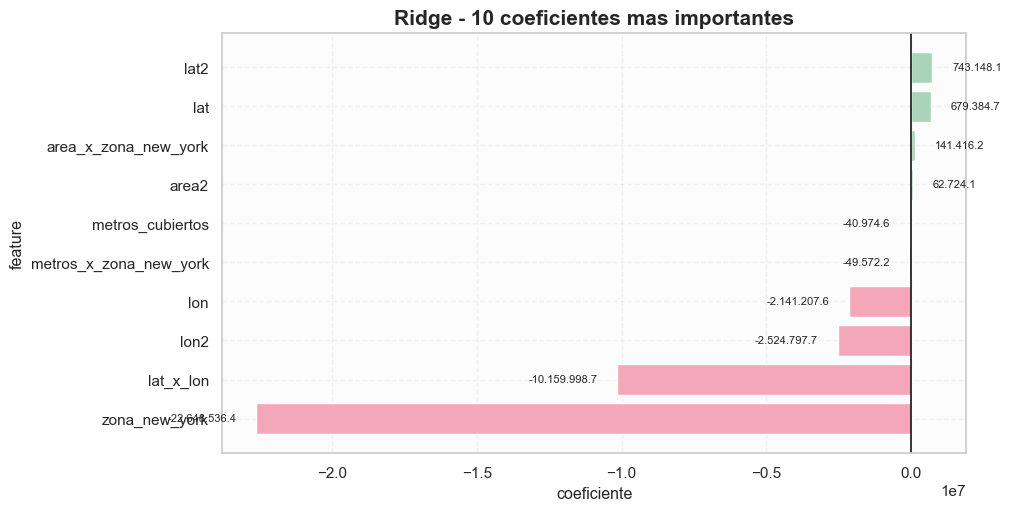

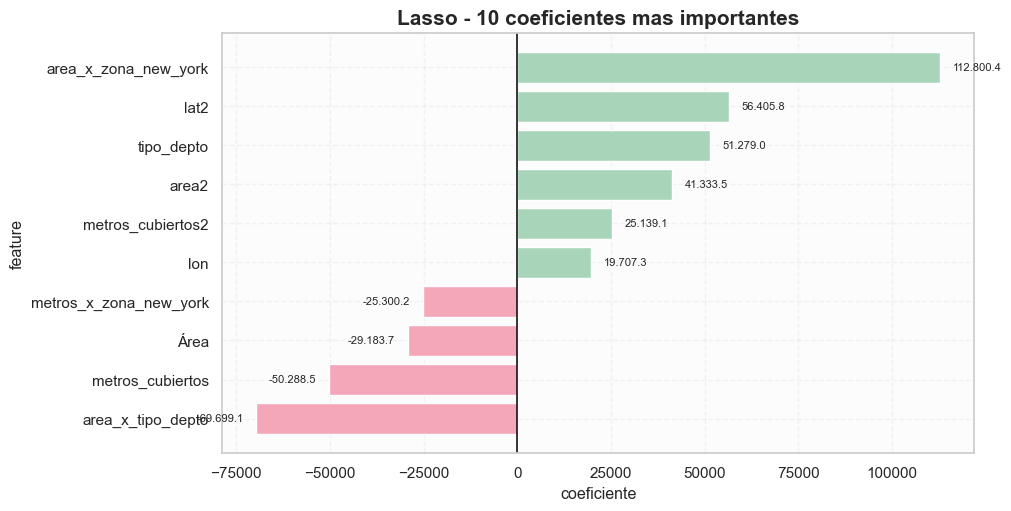

In [16]:
tabla_coef_ridge = modelo_ridge_final.tabla_coeficientes()
tabla_coef_lasso = modelo_lasso_final.tabla_coeficientes()

mayores_ridge, menores_ridge = construir_tablas_coeficientes_extremos(tabla_coef_ridge, n_extremos=10)
mayores_lasso, menores_lasso = construir_tablas_coeficientes_extremos(tabla_coef_lasso, n_extremos=10)

print("10 coeficientes mas importantes de Ridge:")
display(mayores_ridge)
print("10 coeficientes menos importantes de Ridge:")
display(menores_ridge)
print("10 coeficientes mas importantes de Lasso:")
display(mayores_lasso)
print("10 coeficientes menos importantes de Lasso:")
display(menores_lasso)

fig = graficar_importancia_coeficientes(
    tabla_coef_ridge,
    titulo="Ridge - 10 coeficientes mas importantes",
    top_n=10,
)
plt.show()
fig = graficar_importancia_coeficientes(
    tabla_coef_lasso,
    titulo="Lasso - 10 coeficientes mas importantes",
    top_n=10,
)
plt.show()


## 6. Seleccion de modelo y evaluacion de capacidad predictiva

### 6.1) Learning curves para `M1` a `M6`

El cierre del flujo sigue este orden: primero comparo curvas de aprendizaje,
despues selecciono el modelo con mejor balance de generalizacion y recien al final
hago una unica evaluacion en test.


Resumen de learning curves (RMSE):


,modelo,n_train,RMSE_train,RMSE_validation
0,M1,238,"70,149.0130","93,855.1283"
1,M1,416,"74,207.3081","93,267.9316"
2,M1,595,"75,837.6409","92,977.5630"
3,M1,774,"77,431.4163","92,963.8356"
...,...,...,...,...
32,M6,595,"29,999.6629","41,345.6679"
33,M6,774,"30,965.1751","39,248.4302"
34,M6,952,"31,866.5631","38,477.4958"
35,M6,1190,"33,393.8951","38,392.8660"


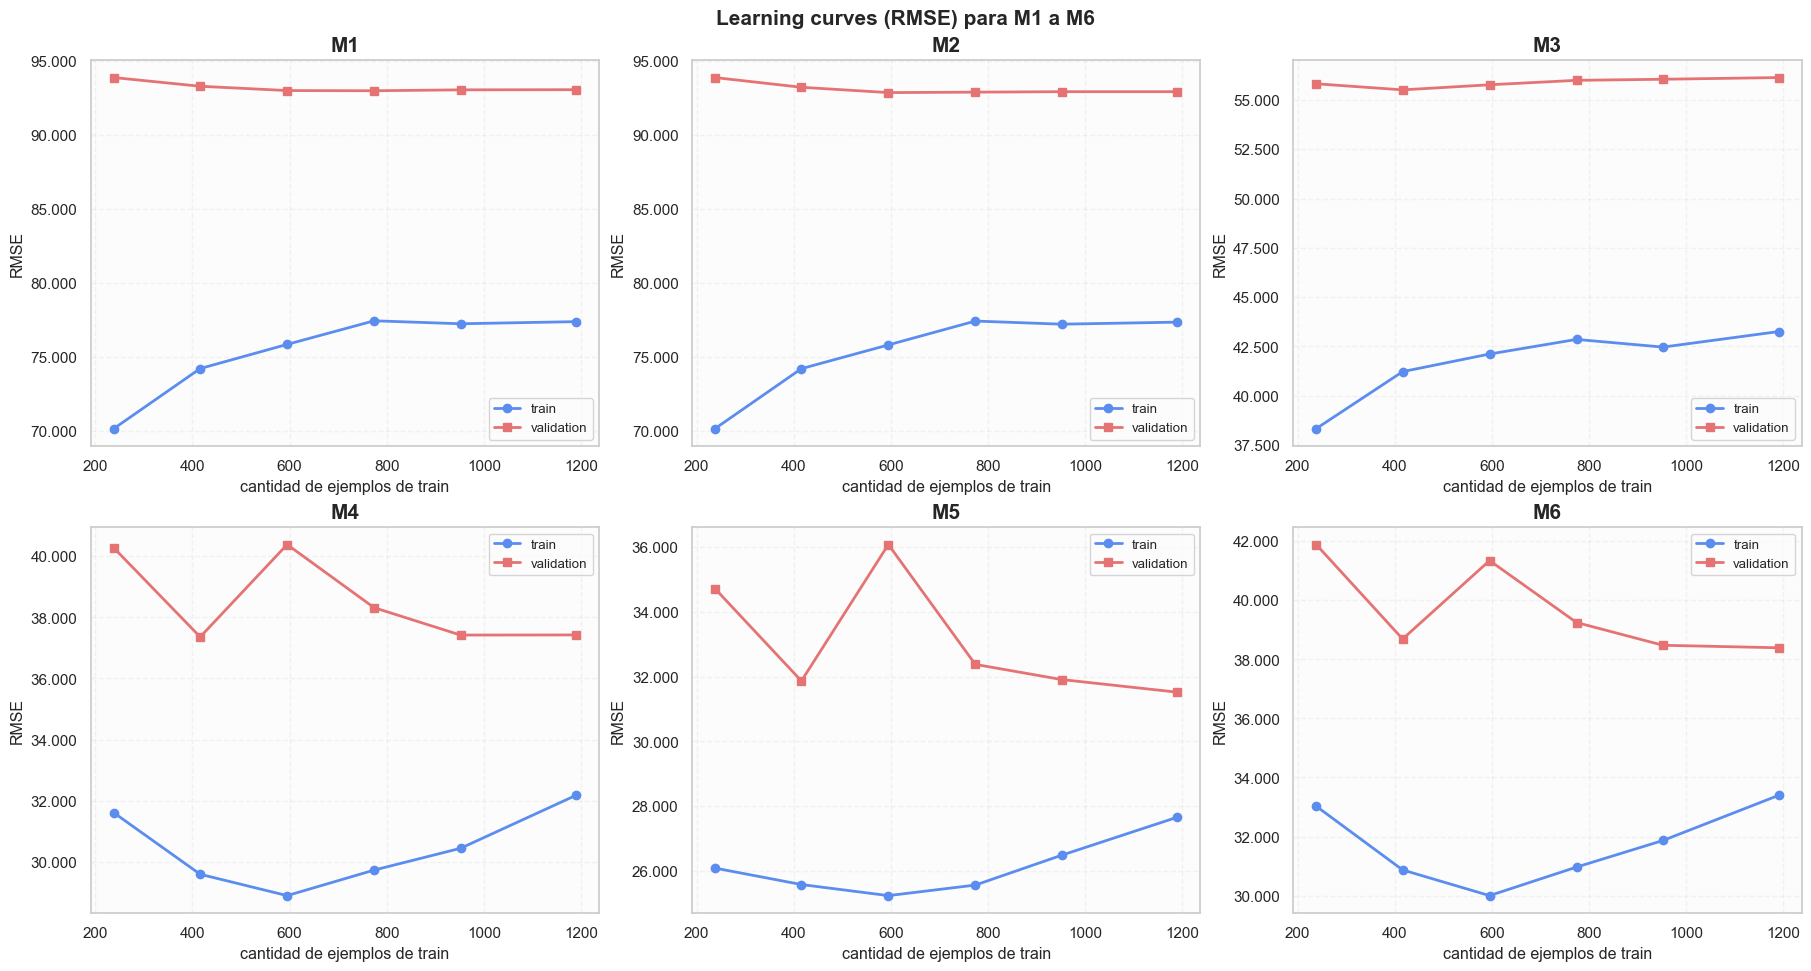

In [17]:
def identidad(df):
    return df.copy()


configuraciones_punto6 = {
    "M1": {
        "builder": identidad,
        "numericas": [AREA_COL],
        "categoricas": [],
        "tipo_modelo": "ols",
        "lambda_reg": 0.0,
    },
    "M2": {
        "builder": identidad,
        "numericas": [AREA_COL],
        "categoricas": ["pileta"],
        "tipo_modelo": "ols",
        "lambda_reg": 0.0,
    },
    "M3": {
        "builder": identidad,
        "numericas": [AREA_COL, "metros_cubiertos", "ambientes", "edad"],
        "categoricas": ["tipo", "zona"],
        "tipo_modelo": "ols",
        "lambda_reg": 0.0,
    },
    "M4": {
        "builder": agregar_features_derivadas_m4,
        "numericas": m4_num,
        "categoricas": m4_cat,
        "tipo_modelo": "ols",
        "lambda_reg": 0.0,
    },
    "M5": {
        "builder": agregar_features_derivadas_m5,
        "numericas": m5_num,
        "categoricas": m5_cat,
        "tipo_modelo": "ols",
        "lambda_reg": 0.0,
    },
    "M6": {
        "builder": agregar_features_derivadas_m4,
        "numericas": m4_num,
        "categoricas": m4_cat,
        "tipo_modelo": "ridge" if nombre_m6 == "Ridge" else "lasso",
        "lambda_reg": lambda_m6,
    },
}

tablas_learning_curves = []
for nombre_modelo, config in configuraciones_punto6.items():
    df_train_modelo = config["builder"](df_train).copy()
    df_validation_modelo = config["builder"](df_validation).copy()

    tabla_modelo = calcular_learning_curve_modelo(
        nombre_modelo=nombre_modelo,
        df_train_modelo=df_train_modelo,
        df_validation_modelo=df_validation_modelo,
        columnas_numericas=config["numericas"],
        columnas_categoricas=config["categoricas"],
        tipo_modelo=config["tipo_modelo"],
        lambda_reg=config["lambda_reg"],
        learning_rate=learning_rate_lasso,
        max_iteraciones=max_iteraciones_lasso,
        tolerancia=tolerancia_lasso,
        fracciones=[0.2, 0.35, 0.5, 0.65, 0.8, 1.0],
        seed=42,
    )
    tablas_learning_curves.append(tabla_modelo)

learning_curves = pd.concat(tablas_learning_curves, ignore_index=True)
print("Resumen de learning curves (RMSE):")
display(learning_curves[["modelo", "n_train", "RMSE_train", "RMSE_validation"]])

fig = graficar_learning_curves_modelos(
    learning_curves,
    metrica="RMSE",
    titulo="Learning curves (RMSE) para M1 a M6",
)
plt.show()


Mirando las learning curves, M1 y M2 quedan cortos bastante rapido y M3 mejora, pero sigue siendo limitado.
En cambio, M4, M5 y M6 aprovechan mejor los datos: el gap entre train y validation baja y validation muestra una tendencia mas estable.


### 6.2) Seleccion del modelo para produccion

La decision final se toma mirando en conjunto las curvas de aprendizaje y las metricas sobre validation.


In [18]:
tabla_seleccion_modelos = pd.DataFrame(
    [
        {
            "modelo": "M1",
            "RMSE_train": artefactos_base["M1"]["resumen"]["RMSE_train"],
            "RMSE_validation": artefactos_base["M1"]["resumen"]["RMSE_validation"],
            "MAE_validation": artefactos_base["M1"]["resumen"]["MAE_validation"],
            "R2_validation": artefactos_base["M1"]["resumen"]["R2_validation"],
        },
        {
            "modelo": "M2",
            "RMSE_train": artefactos_base["M2"]["resumen"]["RMSE_train"],
            "RMSE_validation": artefactos_base["M2"]["resumen"]["RMSE_validation"],
            "MAE_validation": artefactos_base["M2"]["resumen"]["MAE_validation"],
            "R2_validation": artefactos_base["M2"]["resumen"]["R2_validation"],
        },
        {
            "modelo": "M3",
            "RMSE_train": artefactos_base["M3"]["resumen"]["RMSE_train"],
            "RMSE_validation": artefactos_base["M3"]["resumen"]["RMSE_validation"],
            "MAE_validation": artefactos_base["M3"]["resumen"]["MAE_validation"],
            "R2_validation": artefactos_base["M3"]["resumen"]["R2_validation"],
        },
        {
            "modelo": "M4",
            "RMSE_train": resumen_m4["RMSE_train"],
            "RMSE_validation": resumen_m4["RMSE_validation"],
            "MAE_validation": resumen_m4["MAE_validation"],
            "R2_validation": resumen_m4["R2_validation"],
        },
        {
            "modelo": "M5",
            "RMSE_train": resumen_m5["RMSE_train"],
            "RMSE_validation": resumen_m5["RMSE_validation"],
            "MAE_validation": resumen_m5["MAE_validation"],
            "R2_validation": resumen_m5["R2_validation"],
        },
        {
            "modelo": "M6",
            "RMSE_train": resumen_m6["RMSE_train"],
            "RMSE_validation": resumen_m6["RMSE_validation"],
            "MAE_validation": resumen_m6["MAE_validation"],
            "R2_validation": resumen_m6["R2_validation"],
        },
    ]
)
tabla_seleccion_modelos["gap_RMSE_validation_menos_train"] = (
    tabla_seleccion_modelos["RMSE_validation"] - tabla_seleccion_modelos["RMSE_train"]
)
tabla_seleccion_modelos = tabla_seleccion_modelos.sort_values(
    ["RMSE_validation", "MAE_validation"]
).reset_index(drop=True)

modelo_seleccionado = tabla_seleccion_modelos.loc[0, "modelo"]
print(f"Mejor modelo sobre validation: {modelo_seleccionado}")

Mejor modelo sobre validation: M5


En el split actual, el mejor modelo es `M5` porque logra el menor `RMSE` en `validation`
(`31,520`) y tambien el mejor `R2` (`0.911`). Ademas, su brecha entre `train` y `validation`
(`~3,860`) sigue siendo acotada en comparacion con el nivel de error total, por lo que la mejora
no parece venir solo de memorizar ruido.

Esto indica que, en este caso, el bloque extra de features de `M5` agrega senal util y reduce mas
sesgo del que incorpora en varianza. `M4` queda corto frente a esa capacidad extra, mientras que
`M6` no termina superandolo porque la regularizacion estabiliza, pero tambien comprime parte de la
senal que si estaba ayudando en `M5`.

### 6.3) Evaluacion final sobre `casas_test.csv`

Para la evaluacion final vuelvo a entrenar el modelo elegido usando **todo el conjunto de desarrollo**
(`casas_dev.csv`) y recien despues lo aplico sobre `casas_test.csv`.

Asi el test queda reservado para una unica medicion final y no interviene en ninguna decision de modelado.


Metricas finales sobre test:


,modelo,tipo_modelo,lambda,MAE_test,RMSE_test,R2_test
0,M5,ols,0.0000,"19,723.0035","29,975.8459",0.8933


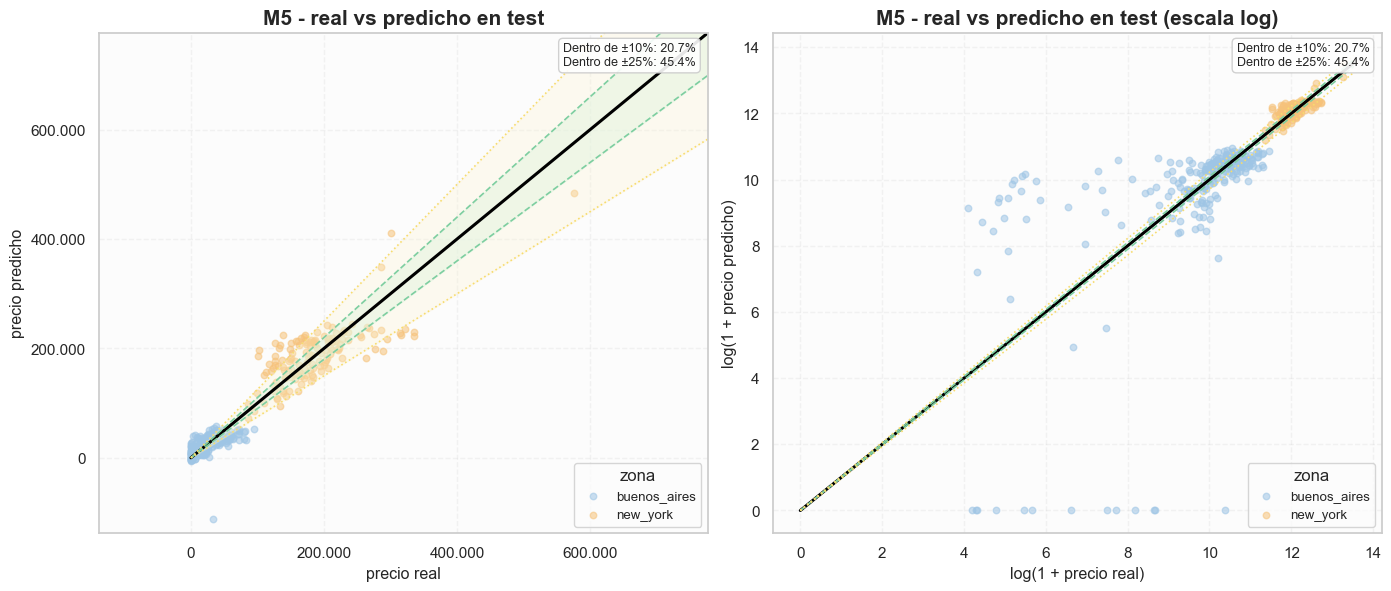

In [19]:
mediana_pisos_dev_final = aprender_mediana_pisos_por_tipo(dataset_base_dev)
mediana_edad_dev_final = aprender_mediana_edad_por_tipo(dataset_base_dev)

df_dev_final = aplicar_imputacion_basica(
    dataset_base_dev,
    mediana_pisos_dev_final,
    mediana_edad_dev_final,
)
df_test_final = aplicar_imputacion_basica(
    dataset_base_test,
    mediana_pisos_dev_final,
    mediana_edad_dev_final,
)

config_final = configuraciones_punto6[modelo_seleccionado]
df_dev_modelo_final = config_final["builder"](df_dev_final).copy()
df_test_modelo_final = config_final["builder"](df_test_final).copy()

resultado_test = ajustar_modelo_con_preprocesamiento(
    df_train_modelo=df_dev_modelo_final,
    df_eval_modelo=df_test_modelo_final,
    columnas_numericas=config_final["numericas"],
    columnas_categoricas=config_final["categoricas"],
    tipo_modelo=config_final["tipo_modelo"],
    lambda_reg=config_final["lambda_reg"],
    learning_rate=learning_rate_lasso,
    max_iteraciones=max_iteraciones_lasso,
    tolerancia=tolerancia_lasso,
)

tabla_metricas_test = pd.DataFrame(
    [
        {
            "modelo": modelo_seleccionado,
            "tipo_modelo": config_final["tipo_modelo"],
            "lambda": config_final["lambda_reg"],
            "MAE_test": resultado_test["metricas_eval"]["MAE"],
            "RMSE_test": resultado_test["metricas_eval"]["RMSE"],
            "R2_test": resultado_test["metricas_eval"]["R2"],
        }
    ]
)

print("Metricas finales sobre test:")
display(tabla_metricas_test)

fig = graficar_real_vs_predicho_panel(
    df_test_modelo_final["precio"],
    resultado_test["pred_eval"],
    zona=df_test_modelo_final["zona"],
    titulo=f"{modelo_seleccionado} - real vs predicho en test",
)
plt.show()


## Nota sobre el experimento de ajuste de precios

Antes de cerrar el TP probe un experimento adicional para corregir algunas
publicaciones sospechosamente baratas mediante una referencia de precio por m2
aprendida solo con `train`.

El experimento modificaba una fraccion acotada del dataset y llegaba a mejoras
muy chicas en validation: `M4`, `M5` y `M6` mejoraban apenas, mientras que `M3`
no mejoraba. Como el ranking final de modelos y la conclusion general del TP no
cambian, saque todo el codigo de ese apendice para que la entrega quede mas
corta y enfocada en el flujo principal con `precio` observado.